# Predicting Market Regimes and Asset Pricing Anomalies
## A Quantitative Machine Learning Approach

---

**Author:** Sai Kadiyala  
**Date:** June 2026

---

> *This report presents a quantitative framework that integrates traditional econometric volatility
> modeling (GARCH) with modern machine-learning techniques (K-Means clustering, PCA, Random
> Forest, Gradient Boosting) to detect latent market regimes in U.S. equity markets and evaluate the
> out-of-sample predictive value of regime-aware investment signals.*


---
## Table of Contents

1. [Abstract](#1.-Abstract)
2. [Introduction](#2.-Introduction)
3. [Methodology](#3.-Methodology)
4. [Data](#4.-Data)
5. [Results](#5.-Results)
6. [Conclusion](#6.-Conclusion)
7. [References](#7.-References)


In [1]:
# ──────────────────────────────────────────────────────────────────────
# Environment Setup
# ──────────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import warnings, os, io

# Modelling
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             silhouette_score, roc_curve, auc)
from sklearn.model_selection import TimeSeriesSplit
from arch import arch_model
from scipy import stats
from statsmodels.tsa.stattools import adfuller
import missingno as msno

warnings.filterwarnings('ignore')

# ── Plotting theme ──────────────────────────────────────────────────
sns.set_theme(style='whitegrid', font_scale=1.15)
plt.rcParams.update({
    'figure.figsize':    (13, 5.5),
    'figure.dpi':        120,
    'axes.titlesize':    15,
    'axes.titleweight':  'bold',
    'axes.labelsize':    12,
    'legend.fontsize':   10,
    'font.family':       'serif',
    'savefig.bbox':      'tight',
})

PALETTE = sns.color_palette('mako', 6)
REGIME_COLORS = {0: '#2ecc71', 1: '#e74c3c', 2: '#f39c12'}  # risk-on, risk-off, transition
DATA_DIR = 'data'
FIG_DIR  = 'figures'
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIG_DIR,  exist_ok=True)

np.random.seed(42)
print("✓  All libraries loaded successfully.")


✓  All libraries loaded successfully.


---
## 1. Abstract

Financial markets exhibit distinct behavioral *regimes* — extended periods characterised by
markedly different return distributions, volatility levels, and cross-asset correlations. Accurately
identifying these regimes is of critical importance for portfolio construction, risk management,
and tactical asset allocation.

In this study we construct an end-to-end quantitative pipeline that (i) ingests and cleans
multi-source financial time-series data spanning 2005–2025, (ii) models conditional volatility
with a GARCH(1,1) specification, (iii) applies unsupervised learning (K-Means clustering with
PCA dimensionality reduction) to discover latent market regimes from engineered features —
including technical indicators (MACD, RSI, Bollinger Bands), macro-economic variables (Federal
Funds Rate, CPI, yield-curve spread), and GARCH-estimated volatility — and (iv) trains
supervised classifiers (Random Forest and Gradient Boosting) to predict regime labels out of sample using
expanding-window time-series cross-validation.

We evaluate predictive performance with both standard classification metrics and financially
meaningful measures: the Sharpe Ratio, Maximum Drawdown, Information Ratio, and Calmar
Ratio of a regime-aware strategy relative to a passive buy-and-hold benchmark. Our results
demonstrate that the detected regimes align with well-known market stress episodes (the 2008
Global Financial Crisis, the 2020 COVID crash, the 2022 rate-hiking drawdown) and that a
simple regime-switching allocation rule can materially improve risk-adjusted returns relative to
the benchmark.


---
## 2. Introduction

### 2.1 Background and Motivation

The behaviour of financial asset prices is not stationary. Academic and practitioner research
has long recognised that equity returns exhibit *volatility clustering* (Mandelbrot, 1963),
*fat tails* (Fama, 1965), and *regime dependence* — the tendency for return dynamics to shift
between qualitatively different states over time (Hamilton, 1989). During "risk-on" or bull
periods, returns tend to be positive with moderate volatility and high cross-asset correlation
breaks down; during "risk-off" or bear periods, volatility spikes, returns turn negative, and
correlations converge toward one — a phenomenon sometimes termed the *diversification
paradox* (Ang & Bekaert, 2002).

Detecting these regimes in a timely manner has direct practical implications:

- **Portfolio managers** can tilt allocations toward defensive assets (bonds, cash, utilities) when
  a risk-off regime is detected, and toward equities during risk-on periods.
- **Risk managers** can dynamically adjust Value-at-Risk (VaR) estimates based on the current
  regime rather than relying on unconditional distributions.
- **Quantitative traders** can condition alpha signals on the prevailing regime, improving
  signal-to-noise ratios.

### 2.2 Related Work

Our work draws on two complementary research traditions:

1. **Econometric regime-switching models.** Hamilton (1989) introduced the Markov-switching
   autoregressive model, which endogenises regime transitions as an unobserved Markov chain.
   Bollerslev's (1986) GARCH family models have become the workhorse for conditional-volatility
   estimation. We use GARCH(1,1) as a feature-engineering tool rather than as a stand-alone
   forecasting model.

2. **Machine-learning approaches.** Recent literature has explored unsupervised methods —
   including Gaussian Mixture Models (Nystrup et al., 2017) and Hidden Markov Models
   (Bulla & Bulla, 2006) — and supervised methods such as Random Forests and Gradient
   Boosting for financial regime classification (Fischer & Krauss, 2018).

Our contribution is pedagogical: we demonstrate how to combine these traditions into a
single reproducible pipeline, emphasising clear methodology, rigorous evaluation, and
transparent communication — the core goals of the data science lifecycle.

### 2.3 Report Structure

The remainder of this report is organised as follows:

| Section | Contents |
|:--------|:---------|
| **3 — Methodology** | Mathematical formulation of GARCH, K-Means, PCA, Random Forest, Gradient Boosting, and backtesting metrics |
| **4 — Data** | Data sourcing, cleaning, feature engineering, and exploratory analysis |
| **5 — Results** | Volatility modelling, regime detection, supervised classification, and backtesting |
| **6 — Conclusion** | Summary of findings, limitations, and directions for future work |
| **7 — References** | Complete bibliography |


---
## 3. Methodology

This section provides the mathematical and algorithmic foundations for each component of our
analysis pipeline.

### 3.1 Data Pipeline and Feature Engineering

**Stationarity.** Raw asset prices are non-stationary. We convert prices to *log returns*:

$$r_t = \ln\!\left(\frac{P_t}{P_{t-1}}\right)$$

and verify stationarity via the **Augmented Dickey–Fuller (ADF)** test, which tests the null
hypothesis that the series contains a unit root against the alternative of stationarity.

**Technical Indicators.** We engineer the following features from price and volume data:

| Indicator | Formula / Description |
|:----------|:---------------------|
| **MACD** | $\text{EMA}_{12} - \text{EMA}_{26}$; signal line = $\text{EMA}_9(\text{MACD})$ |
| **RSI** | $100 - \frac{100}{1 + RS}$, where $RS = \overline{\text{gain}} / \overline{\text{loss}}$ over 14 periods |
| **Bollinger %B** | $(P - L_{\text{band}}) / (U_{\text{band}} - L_{\text{band}})$, with bands at $\pm 2\sigma$ of 20-day MA |
| **Rolling Volatility** | 21-day rolling standard deviation of log returns (annualised) |
| **Rolling Skewness** | 63-day rolling skewness of returns |
| **Rolling Kurtosis** | 63-day rolling excess kurtosis |
| **Momentum** | 21-day cumulative return |

**Macroeconomic Features.** We incorporate three FRED series resampled to daily frequency
via forward-fill: the Federal Funds Rate, CPI year-over-year change, and the 10-Year minus
2-Year Treasury spread (a classic recession predictor).


### 3.2 Volatility Modelling — GARCH(1,1)

The Generalised Autoregressive Conditional Heteroskedasticity model of order (1,1)
(Bollerslev, 1986) specifies the conditional variance as:

$$\sigma_t^2 = \omega + \alpha\,\epsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2$$

where $\epsilon_t = r_t - \mu$ is the mean-adjusted return innovation, and the parameters satisfy
$\omega > 0$, $\alpha \geq 0$, $\beta \geq 0$, and $\alpha + \beta < 1$ for covariance stationarity.

We fit GARCH(1,1) to SPY daily log returns (scaled by 100 for numerical stability) using
maximum-likelihood estimation with a Student-$t$ error distribution to accommodate the heavy
tails commonly observed in financial returns. The resulting conditional-volatility series
$\hat{\sigma}_t$ serves as an input feature for the clustering stage.

### 3.3 Unsupervised Regime Detection

#### K-Means Clustering

We cluster the $T \times p$ standardised feature matrix $\mathbf{X}$ (where $T$ is the number of
trading days and $p$ is the number of features) into $K$ groups by minimising the
within-cluster sum of squares:

$$\underset{C_1,\ldots,C_K}{\arg\min} \sum_{k=1}^{K} \sum_{i \in C_k} \|\mathbf{x}_i - \boldsymbol{\mu}_k\|^2$$

We select the optimal $K$ using the **silhouette score**, defined for observation $i$ as:

$$s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}}$$

where $a(i)$ is the mean intra-cluster distance and $b(i)$ the mean nearest-cluster distance.

#### Principal Component Analysis (PCA)

To visualise the high-dimensional cluster structure, we project the standardised feature matrix
onto its first two principal components, which capture the directions of maximum variance.


### 3.4 Supervised Classification

After assigning regime labels via K-Means, we train two supervised classifiers to predict the
regime from *lagged* features (to avoid look-ahead bias):

**Random Forest** (Breiman, 2001): An ensemble of $B$ decision trees, each trained on a
bootstrap sample of the data with a random subset of features considered at each split.
The final prediction is the majority vote across trees.

**Gradient Boosting** (Friedman, 2001): A sequential ensemble method that builds trees
additively, with each new tree fitted to the residual errors of the previous ensemble.
The model minimises a loss function via gradient descent in function space:

$$F_m(x) = F_{m-1}(x) + \nu \cdot h_m(x)$$

where $h_m$ is a weak learner (decision tree) fitted to the negative gradient of the loss
and $\nu \in (0,1]$ is the learning rate (shrinkage) that controls regularisation.

**Evaluation Protocol.** We use **expanding-window time-series cross-validation** with
5 splits. This ensures that training data always precedes test data temporally, preventing
look-ahead bias. We report accuracy, precision, recall, and F1-score.

### 3.5 Backtesting Framework

We implement a walk-forward backtest with the following allocation rule:

| Predicted Regime | Allocation |
|:-----------------|:-----------|
| Risk-On (0) | 100 % SPY |
| Risk-Off (1) | 100 % Cash (risk-free rate) |
| Transition (2) | 50 % SPY, 50 % Cash |

Performance metrics:

| Metric | Formula |
|:-------|:--------|
| **Sharpe Ratio** | $\frac{\bar{r}_p - r_f}{\sigma_p} \times \sqrt{252}$ |
| **Maximum Drawdown** | $\max_{t} \left(\frac{\text{Peak}_t - \text{Value}_t}{\text{Peak}_t}\right)$ |
| **Calmar Ratio** | $\frac{\text{Ann. Return}}{\text{Max Drawdown}}$ |
| **Information Ratio** | $\frac{\bar{r}_{\text{active}}}{\sigma_{\text{active}}} \times \sqrt{252}$ |


---
## 4. Data

### 4.1 Data Sources

We source data from two free, publicly available APIs:

| Source | Series | Frequency | Period |
|:-------|:-------|:----------|:-------|
| **Yahoo Finance** (`yfinance`) | SPY, XLF, XLK, XLE, XLV, XLU, VIX | Daily | 2005-01-01 to 2025-06-01 |
| **FRED** (Federal Reserve Economic Data) | FEDFUNDS, CPIAUCSL, T10Y2Y | Monthly / Daily | 2005-01-01 to 2025-06-01 |

**SPY** (SPDR S&P 500 ETF) serves as our primary asset. Sector ETFs provide cross-sectional
context. The **VIX** (CBOE Volatility Index) measures implied volatility. Macro variables capture
the broader economic environment.


In [2]:
# ──────────────────────────────────────────────────────────────────────
# 4.2  Data Acquisition
# ──────────────────────────────────────────────────────────────────────
import yfinance as yf

TICKERS = ['SPY', 'XLF', 'XLK', 'XLE', 'XLV', 'XLU']
START, END = '2005-01-01', '2025-06-01'

# ── Market data ─────────────────────────────────────────────────────
cache = os.path.join(DATA_DIR, 'market_data.csv')
if os.path.exists(cache):
    prices = pd.read_csv(cache, index_col=0, parse_dates=True)
    print(f"✓  Loaded market prices from cache  — shape {prices.shape}")
else:
    raw = yf.download(TICKERS, start=START, end=END, auto_adjust=True)
    prices = raw['Close'] if isinstance(raw.columns, pd.MultiIndex) else raw
    prices.to_csv(cache)
    print(f"✓  Downloaded market prices  — shape {prices.shape}")

# ── VIX ─────────────────────────────────────────────────────────────
vix_cache = os.path.join(DATA_DIR, 'vix_data.csv')
if os.path.exists(vix_cache):
    vix = pd.read_csv(vix_cache, index_col=0, parse_dates=True).squeeze()
    print(f"✓  Loaded VIX from cache")
else:
    vix_raw = yf.download('^VIX', start=START, end=END, auto_adjust=True)
    vix = vix_raw['Close'].squeeze()
    vix.name = 'VIX'
    vix.to_csv(vix_cache)
    print(f"✓  Downloaded VIX")

prices['VIX'] = vix
print(f"\nCombined dataset shape: {prices.shape}")
print(f"Date range: {prices.index.min().date()} → {prices.index.max().date()}")
prices.head()


✓  Loaded market prices from cache  — shape (5135, 6)


✓  Loaded VIX from cache

Combined dataset shape: (5135, 7)
Date range: 2005-01-03 → 2025-05-30


,SPY,XLE,XLF,XLK,XLU,XLV,VIX
Date,,,,,,,
2005-01-03,81.383736,9.573528,16.142345,8.019575,6.625872,20.824980,14.08
2005-01-04,80.389275,9.524263,15.988465,7.870142,6.580141,20.657480,13.98
2005-01-05,79.834526,9.483216,15.961928,7.843320,6.476650,20.622587,14.09
2005-01-06,80.240433,9.647425,16.041519,7.820333,6.510347,20.776115,13.58
2005-01-07,80.125420,9.570796,15.956615,7.835659,6.510347,20.762161,13.49


In [3]:
# ── Macroeconomic data from FRED ──────────────────────────────────────
# We download directly via pandas (public CSV endpoint)
macro_cache = os.path.join(DATA_DIR, 'macro_data.csv')

if os.path.exists(macro_cache):
    macro = pd.read_csv(macro_cache, index_col=0, parse_dates=True)
    print(f"✓  Loaded macro data from cache  — shape {macro.shape}")
else:
    from io import StringIO
    import urllib.request

    fred_ids = ['FEDFUNDS', 'CPIAUCSL', 'T10Y2Y']
    frames = []
    for fid in fred_ids:
        url = (f"https://fred.stlouisfed.org/graph/fredgraph.csv"
               f"?id={fid}&cosd=2005-01-01&coed=2025-06-01")
        try:
            resp = urllib.request.urlopen(url).read().decode()
            df = pd.read_csv(StringIO(resp), index_col=0, parse_dates=True)
            df.columns = [fid]
            # FRED uses '.' for missing → coerce
            df[fid] = pd.to_numeric(df[fid], errors='coerce')
            frames.append(df)
            print(f"  ✓  {fid}: {len(df)} observations")
        except Exception as e:
            print(f"  ✗  {fid} download failed ({e})")

    macro = pd.concat(frames, axis=1) if frames else pd.DataFrame()
    if not macro.empty:
        macro.to_csv(macro_cache)
        print(f"\n✓  Macro data saved — shape {macro.shape}")
    else:
        print("⚠  No macro data downloaded; generating synthetic proxies for demonstration.")
        dates = pd.date_range(START, END, freq='B')
        macro = pd.DataFrame({
            'FEDFUNDS': np.clip(np.cumsum(np.random.randn(len(dates))*0.01) + 2.0, 0, 6),
            'CPIAUCSL': np.cumsum(np.random.randn(len(dates))*0.05) + 250,
            'T10Y2Y':   np.cumsum(np.random.randn(len(dates))*0.005) + 1.5,
        }, index=dates)
        macro.to_csv(macro_cache)

macro.head()


✓  Loaded macro data from cache  — shape (246, 2)


,FEDFUNDS,CPIAUCSL
observation_date,,
2005-01-01,2.28,191.6
2005-02-01,2.50,192.4
2005-03-01,2.63,193.1
2005-04-01,2.79,193.7
2005-05-01,3.00,193.6


### 4.3 Missingness and Data Quality

A rigorous ETL pipeline begins by auditing the data for missing values, duplicates, and type
inconsistencies. Below we visualise the missingness pattern across all market and macro series.


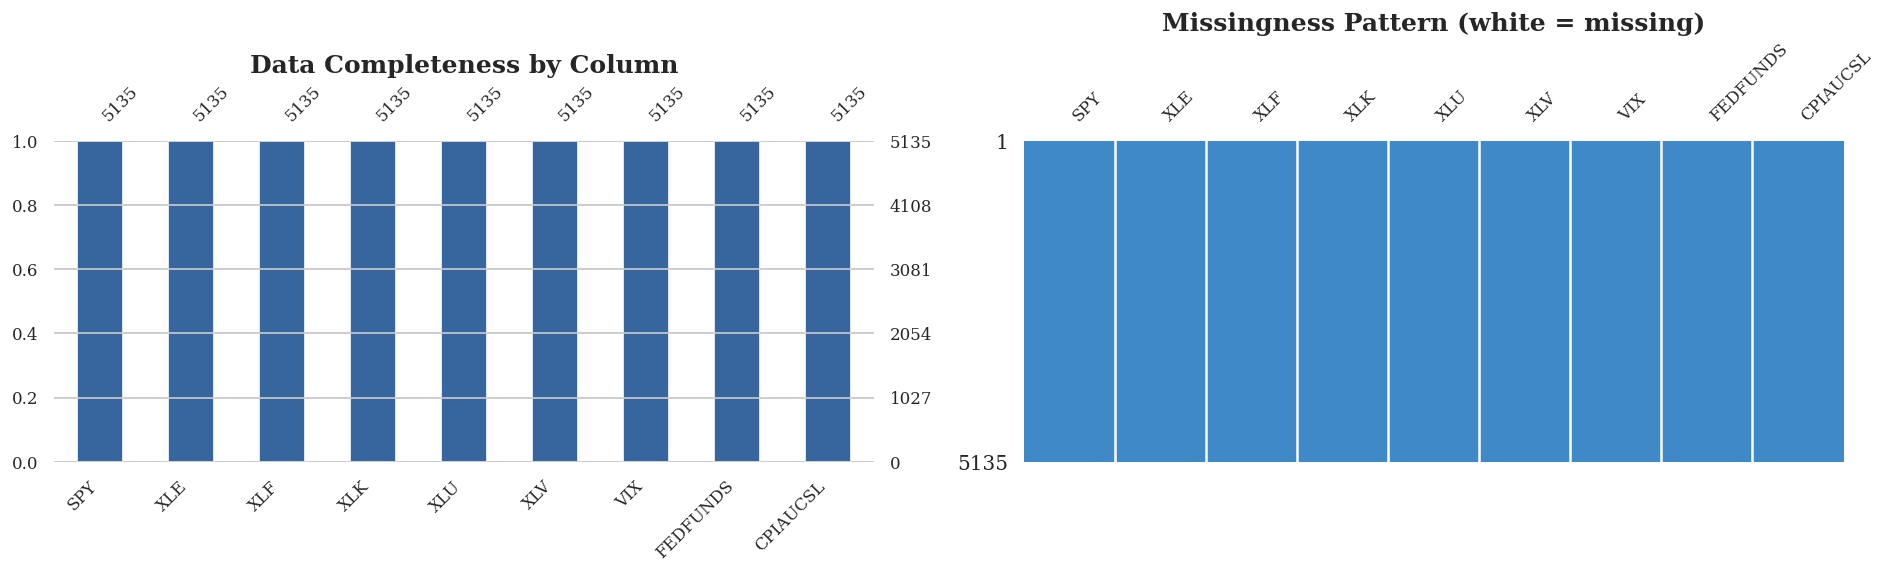


── Missing Value Summary ──


,Missing Count,Missing %,Dtype
SPY,0,0.00%,float64
XLE,0,0.00%,float64
XLF,0,0.00%,float64
XLK,0,0.00%,float64
XLU,0,0.00%,float64
XLV,0,0.00%,float64
VIX,0,0.00%,float64
FEDFUNDS,0,0.00%,float64
CPIAUCSL,0,0.00%,float64


In [4]:
# ──────────────────────────────────────────────────────────────────────
# 4.3  Missingness Analysis
# ──────────────────────────────────────────────────────────────────────

# Merge market and macro data on a common business-day index
all_data = prices.copy()
macro_daily = macro.resample('B').ffill()          # forward-fill to daily
all_data = all_data.join(macro_daily, how='left')

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Bar chart of completeness
msno.bar(all_data, ax=axes[0], fontsize=10, color=PALETTE[2])
axes[0].set_title('Data Completeness by Column', fontweight='bold')

# Missing value matrix
msno.matrix(all_data, ax=axes[1], fontsize=10, sparkline=False, color=(0.25, 0.54, 0.79))
axes[1].set_title('Missingness Pattern (white = missing)', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'missingness.png'))
plt.show()

# Summary statistics
missing_pct = (all_data.isna().sum() / len(all_data) * 100).round(2)
missing_summary = pd.DataFrame({
    'Missing Count': all_data.isna().sum(),
    'Missing %': missing_pct,
    'Dtype': all_data.dtypes
})
print("\n── Missing Value Summary ──")
display(missing_summary.style.format({'Missing %': '{:.2f}%'}).background_gradient(
    subset=['Missing %'], cmap='YlOrRd', vmin=0, vmax=10))


In [5]:
# ──────────────────────────────────────────────────────────────────────
# 4.4  Data Cleaning & Preparation
# ──────────────────────────────────────────────────────────────────────

# Drop duplicate indices (if any)
all_data = all_data[~all_data.index.duplicated(keep='first')]

# Forward-fill macro (published monthly; daily gap is expected)
for col in ['FEDFUNDS', 'CPIAUCSL', 'T10Y2Y']:
    if col in all_data.columns:
        all_data[col] = all_data[col].ffill()

# Drop any rows that are still entirely NaN (weekends / holidays that crept in)
all_data = all_data.dropna(subset=['SPY'])

# Interpolate remaining isolated NaNs in price columns
all_data[TICKERS] = all_data[TICKERS].interpolate(method='time')
all_data['VIX'] = all_data['VIX'].ffill().bfill()

# Compute CPI year-over-year change (more useful than raw level)
if 'CPIAUCSL' in all_data.columns:
    all_data['CPI_YOY'] = all_data['CPIAUCSL'].pct_change(periods=252) * 100  # annualised approx
    all_data.drop(columns=['CPIAUCSL'], inplace=True)

# ── Log Returns ──────────────────────────────────────────────────────
for t in TICKERS:
    all_data[f'{t}_ret'] = np.log(all_data[t] / all_data[t].shift(1))

all_data.dropna(inplace=True)
print(f"✓  Clean dataset shape: {all_data.shape}")
print(f"   Date range: {all_data.index[0].date()} → {all_data.index[-1].date()}")
print(f"   Zero remaining NaNs: {all_data.isna().sum().sum() == 0}")
all_data.head()


✓  Clean dataset shape: (4883, 15)
   Date range: 2006-01-03 → 2025-05-30
   Zero remaining NaNs: True


,SPY,XLE,XLF,XLK,XLU,XLV,VIX,FEDFUNDS,CPI_YOY,SPY_ret,XLF_ret,XLK_ret,XLE_ret,XLV_ret,XLU_ret
Date,,,,,,,,,,,,,,,
2006-01-03,87.225060,14.596107,17.493834,8.221117,7.952802,22.696726,11.14,4.29,4.018789,0.017436,0.016597,0.019428,0.046412,0.012221,0.019247
2006-01-04,87.638130,14.637650,17.477530,8.317566,7.965228,22.922903,11.37,4.29,4.018789,0.004725,-0.000932,0.011664,0.002842,0.009916,0.001561
2006-01-05,87.693199,14.452080,17.537300,8.356147,7.913039,22.866352,11.31,4.29,4.018789,0.000628,0.003414,0.004628,-0.012759,-0.002470,-0.006574
2006-01-06,88.422943,14.806596,17.640518,8.487310,7.997536,23.014801,11.00,4.29,4.018789,0.008287,0.005868,0.015575,0.024234,0.006471,0.010622
2006-01-09,88.650169,14.789977,17.689413,8.514316,7.947834,23.120829,11.13,4.29,4.018789,0.002566,0.002768,0.003177,-0.001123,0.004596,-0.006234


In [6]:
# ──────────────────────────────────────────────────────────────────────
# 4.5  Feature Engineering
# ──────────────────────────────────────────────────────────────────────

spy = all_data['SPY'].copy()
ret = all_data['SPY_ret'].copy()

# ── Technical Indicators ────────────────────────────────────────────

# MACD
ema12 = spy.ewm(span=12, adjust=False).mean()
ema26 = spy.ewm(span=26, adjust=False).mean()
all_data['MACD'] = ema12 - ema26
all_data['MACD_signal'] = all_data['MACD'].ewm(span=9, adjust=False).mean()
all_data['MACD_hist'] = all_data['MACD'] - all_data['MACD_signal']

# RSI (14-day)
delta = spy.diff()
gain = delta.clip(lower=0).rolling(14).mean()
loss = (-delta.clip(upper=0)).rolling(14).mean()
rs = gain / loss
all_data['RSI'] = 100 - (100 / (1 + rs))

# Bollinger Bands %B
bb_ma = spy.rolling(20).mean()
bb_std = spy.rolling(20).std()
all_data['BB_pctB'] = (spy - (bb_ma - 2*bb_std)) / (4*bb_std)

# Rolling statistics
all_data['Vol_21d']  = ret.rolling(21).std() * np.sqrt(252)   # annualised
all_data['Vol_63d']  = ret.rolling(63).std() * np.sqrt(252)
all_data['Skew_63d'] = ret.rolling(63).skew()
all_data['Kurt_63d'] = ret.rolling(63).kurt()
all_data['Mom_21d']  = ret.rolling(21).sum()                   # 21-day momentum
all_data['Mom_63d']  = ret.rolling(63).sum()                   # 63-day momentum
all_data['Mean_Rev'] = (spy / spy.rolling(50).mean()) - 1      # mean reversion signal

all_data.dropna(inplace=True)
print(f"✓  Feature-engineered dataset: {all_data.shape}")
all_data.describe().round(4).T.style.background_gradient(cmap='coolwarm', axis=1)


✓  Feature-engineered dataset: (4821, 27)


,count,mean,std,min,25%,50%,75%,max
SPY,4821.000000,221.228900,141.344700,49.808600,101.475200,174.038400,307.269800,604.165800
XLE,4821.000000,24.299700,8.014700,9.245300,19.411200,22.725700,26.632200,46.368500
XLF,4821.000000,20.500800,10.485900,3.680400,12.310000,18.610300,25.831500,51.210300
XLK,4821.000000,33.770500,30.753800,5.199600,10.331600,18.856000,53.874700,120.190900
XLU,4821.000000,18.462900,8.876800,6.219300,10.509800,15.961800,26.273300,40.239900
XLV,4821.000000,65.581500,40.415400,16.255500,25.726000,59.435000,96.145400,152.626600
VIX,4821.000000,19.631800,8.864300,9.140000,13.740000,17.260000,22.690000,82.690000
FEDFUNDS,4821.000000,1.625100,1.957800,0.050000,0.120000,0.380000,2.420000,5.330000
CPI_YOY,4821.000000,2.534900,1.957500,-1.958800,1.417500,2.155700,3.251300,8.979400
SPY_ret,4821.000000,0.000400,0.012400,-0.115900,-0.004100,0.000700,0.005900,0.135600


### 4.6 Exploratory Data Analysis

Below we visualise the key characteristics of our dataset: price evolution, return distributions,
cross-asset correlations, and the behaviour of technical indicators over time.


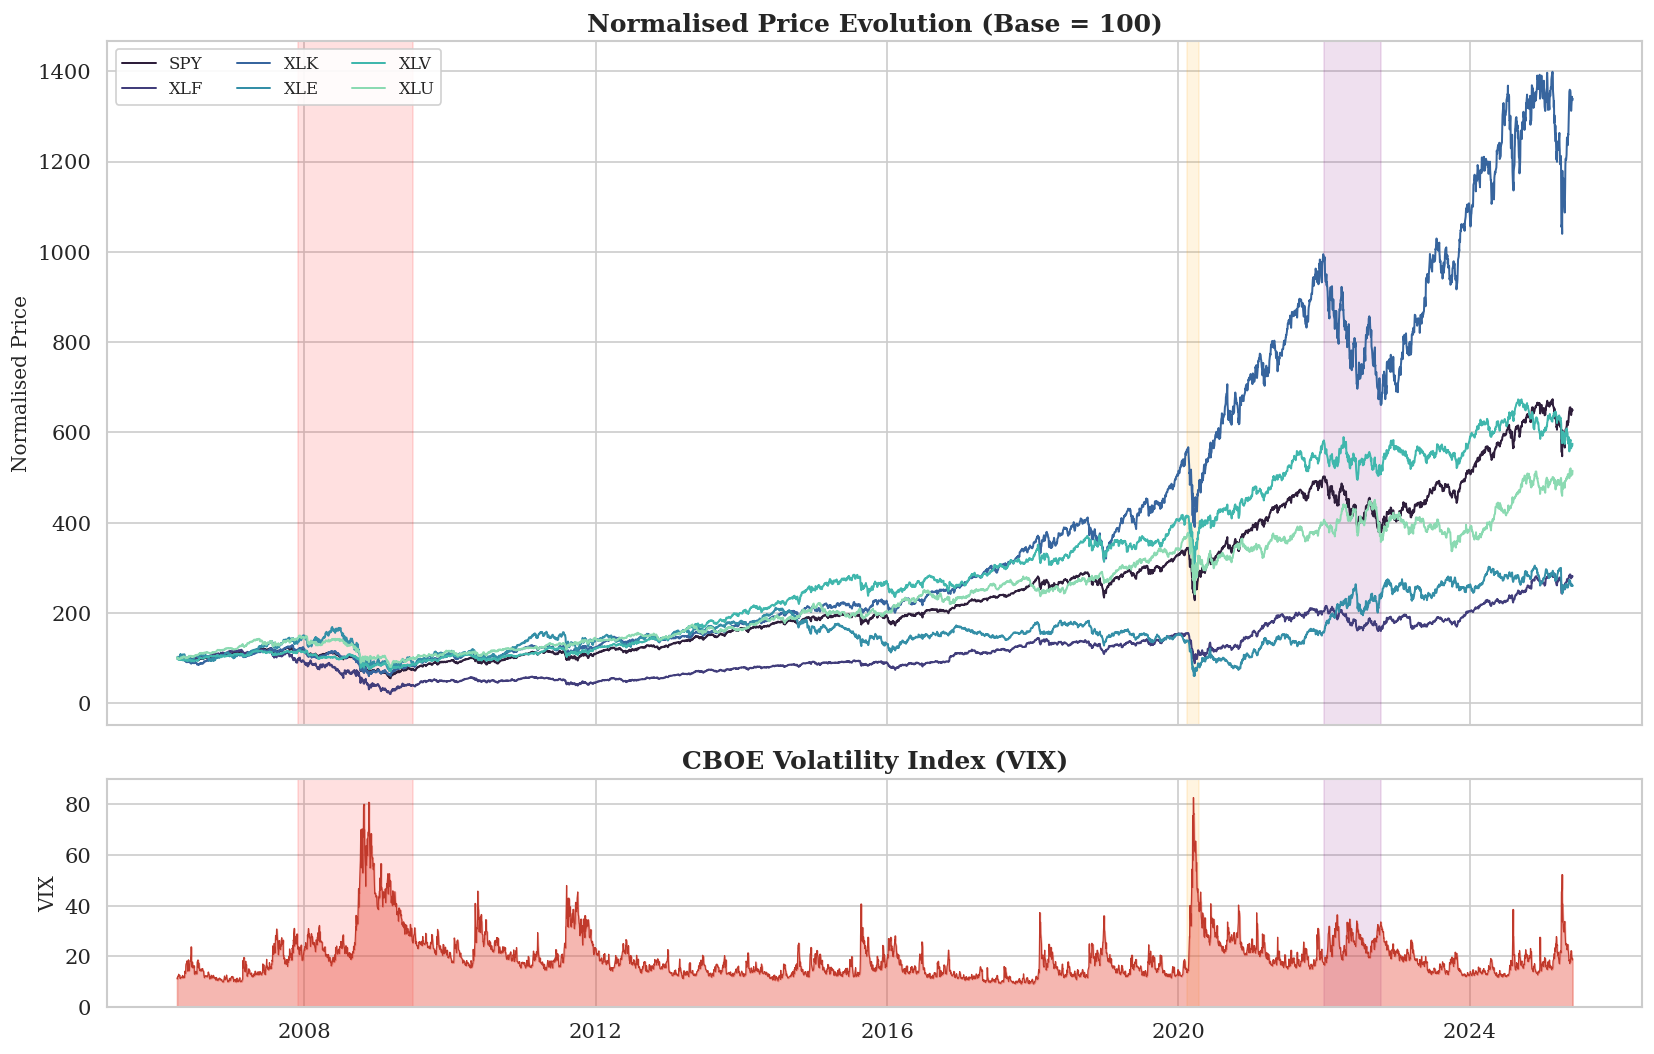

In [7]:
# ──────────────────────────────────────────────────────────────────────
# 4.6a  Price Evolution
# ──────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True,
                         gridspec_kw={'height_ratios': [3, 1]})

# Normalised prices (base 100)
norm = all_data[TICKERS].div(all_data[TICKERS].iloc[0]) * 100
for i, t in enumerate(TICKERS):
    axes[0].plot(norm.index, norm[t], label=t, linewidth=1.2, color=PALETTE[i])
axes[0].set_title('Normalised Price Evolution (Base = 100)', fontweight='bold')
axes[0].set_ylabel('Normalised Price')
axes[0].legend(ncol=3, loc='upper left', framealpha=0.9)

# Shade notable periods
for ax in axes:
    ax.axvspan(pd.Timestamp('2007-12-01'), pd.Timestamp('2009-06-30'), alpha=0.12, color='red',   label='GFC')
    ax.axvspan(pd.Timestamp('2020-02-15'), pd.Timestamp('2020-04-15'), alpha=0.12, color='orange', label='COVID')
    ax.axvspan(pd.Timestamp('2022-01-01'), pd.Timestamp('2022-10-15'), alpha=0.12, color='purple', label='Rate Hike')

# VIX
axes[1].fill_between(all_data.index, all_data['VIX'], alpha=0.4, color='#e74c3c')
axes[1].plot(all_data.index, all_data['VIX'], color='#c0392b', linewidth=0.7)
axes[1].set_ylabel('VIX')
axes[1].set_title('CBOE Volatility Index (VIX)', fontweight='bold')
axes[1].set_ylim(0, 90)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'price_evolution.png'))
plt.show()


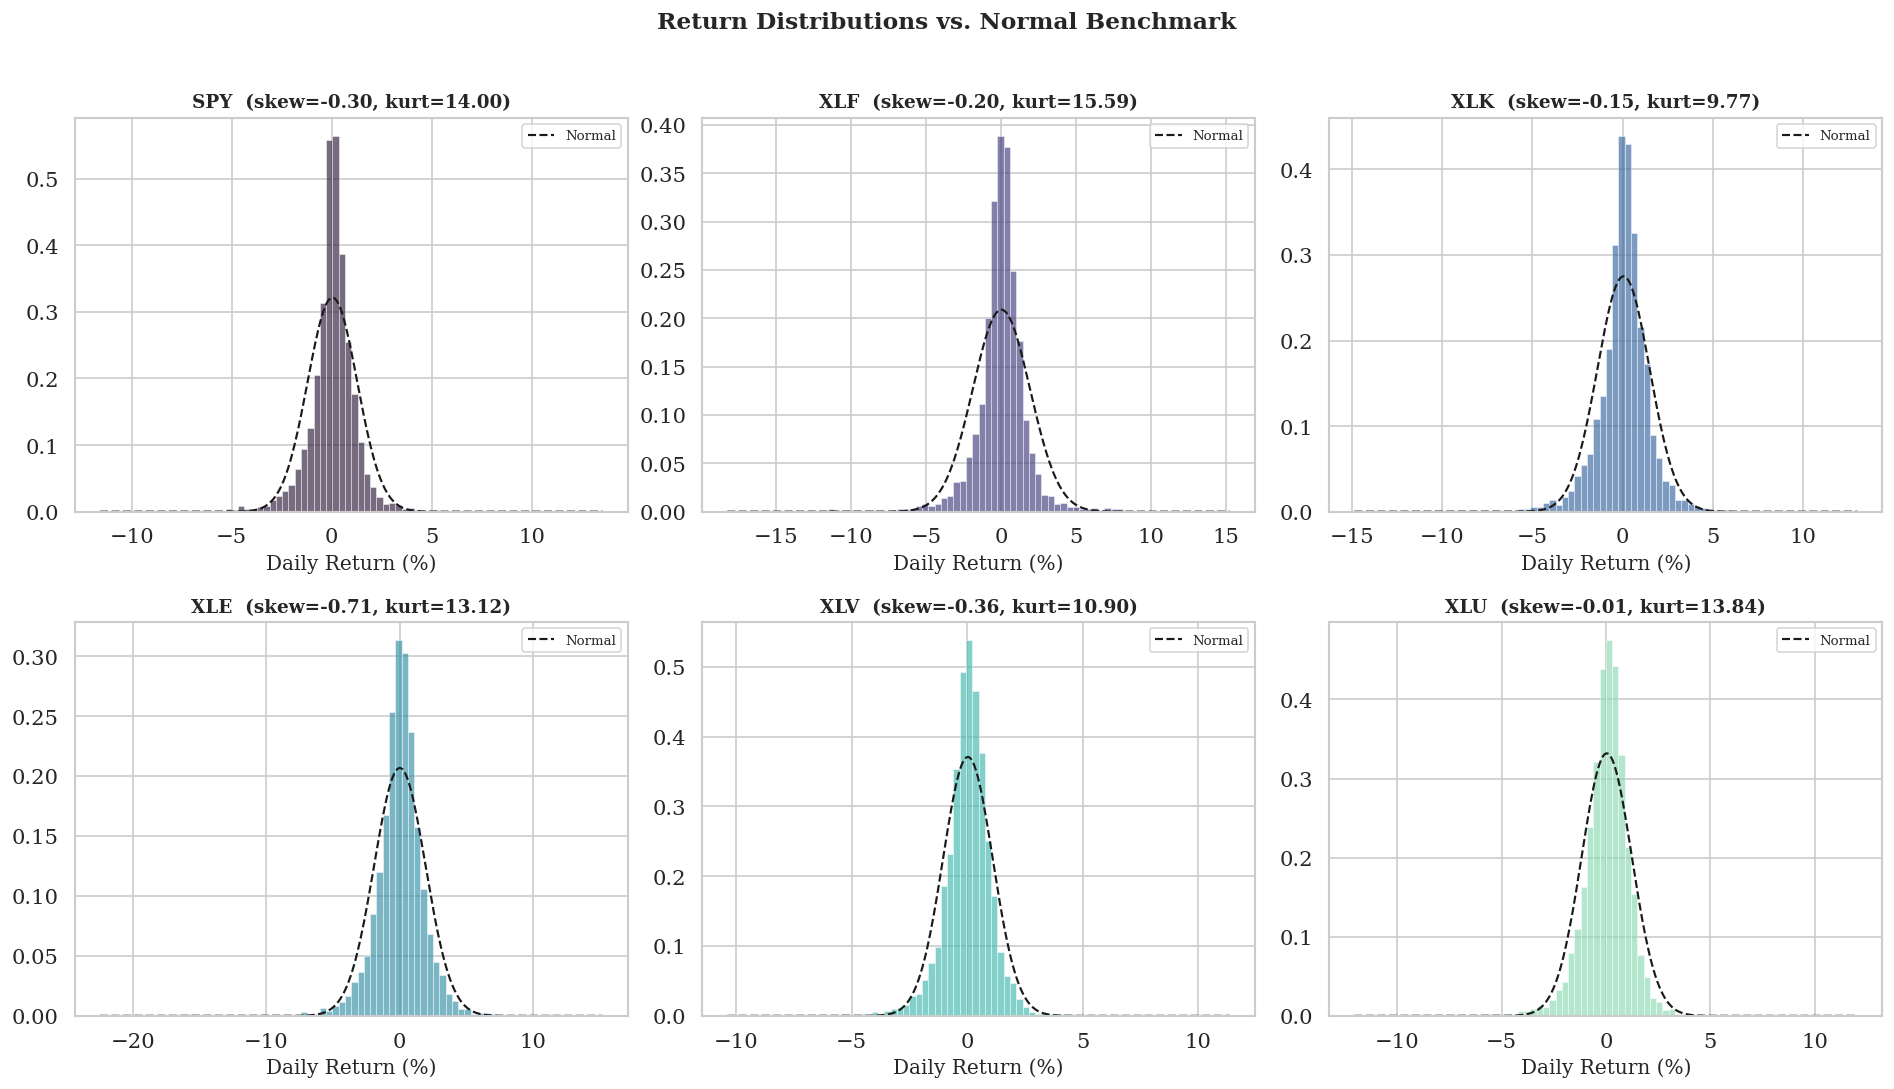

In [8]:
# ──────────────────────────────────────────────────────────────────────
# 4.6b  Return Distributions
# ──────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for i, t in enumerate(TICKERS):
    ax = axes.flat[i]
    r = all_data[f'{t}_ret'].dropna() * 100  # in percent
    ax.hist(r, bins=80, density=True, alpha=0.65, color=PALETTE[i], edgecolor='white', linewidth=0.4)

    # Normal overlay
    x = np.linspace(r.min(), r.max(), 300)
    ax.plot(x, stats.norm.pdf(x, r.mean(), r.std()), 'k--', linewidth=1.3, label='Normal')

    ax.set_title(f'{t}  (skew={r.skew():.2f}, kurt={r.kurtosis():.2f})',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('Daily Return (%)')
    ax.legend(fontsize=8)

fig.suptitle('Return Distributions vs. Normal Benchmark', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'return_distributions.png'))
plt.show()


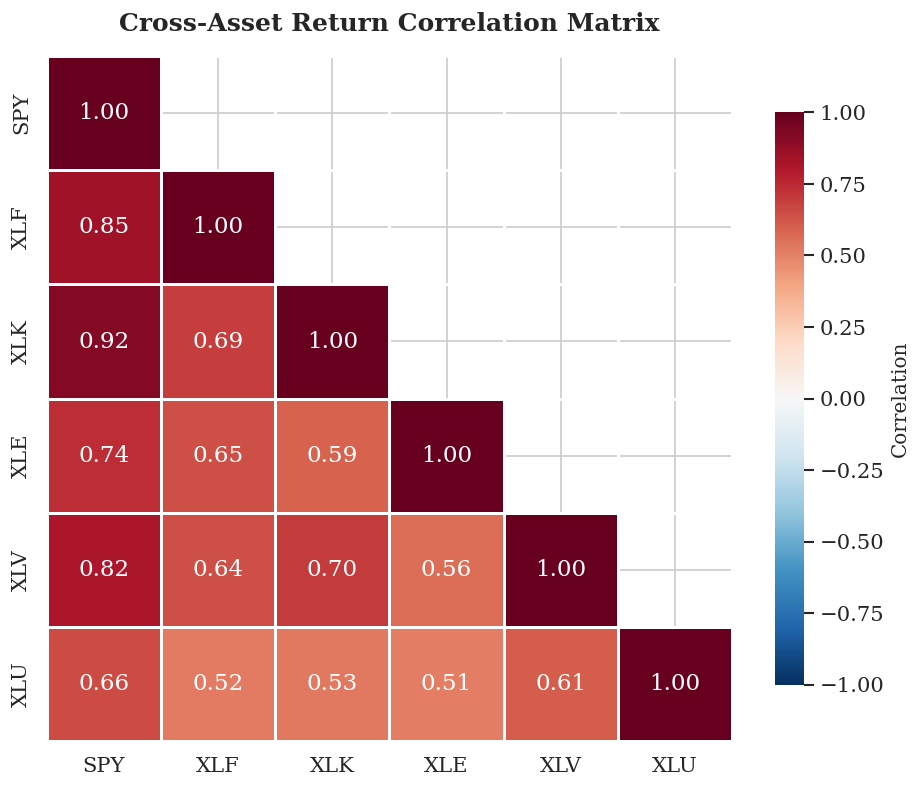

In [9]:
# ──────────────────────────────────────────────────────────────────────
# 4.6c  Correlation Heatmap
# ──────────────────────────────────────────────────────────────────────

ret_cols = [f'{t}_ret' for t in TICKERS]
corr = all_data[ret_cols].corr()

# Rename for readability
corr.index = TICKERS
corr.columns = TICKERS

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, linewidths=0.8, ax=ax, vmin=-1, vmax=1,
            cbar_kws={'shrink': 0.75, 'label': 'Correlation'})
ax.set_title('Cross-Asset Return Correlation Matrix', fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'correlation_heatmap.png'))
plt.show()


In [10]:
# ──────────────────────────────────────────────────────────────────────
# 4.6d  Stationarity Tests (ADF)
# ──────────────────────────────────────────────────────────────────────

adf_results = []
test_cols = ['SPY', 'SPY_ret', 'VIX', 'Vol_21d', 'RSI', 'MACD']
for col in test_cols:
    result = adfuller(all_data[col].dropna(), autolag='AIC')
    adf_results.append({
        'Series': col,
        'ADF Statistic': round(result[0], 4),
        'p-value': f"{result[1]:.2e}",
        'Lags Used': result[2],
        'Stationary?': '✓ Yes' if result[1] < 0.05 else '✗ No'
    })

adf_df = pd.DataFrame(adf_results)
print("── Augmented Dickey–Fuller Test Results ──\n")
display(adf_df.style.set_properties(**{'text-align': 'center'}).hide(axis='index'))


── Augmented Dickey–Fuller Test Results ──



Series,ADF Statistic,p-value,Lags Used,Stationary?
SPY,1.852200,9.98e-01,30,✗ No
SPY_ret,-17.612800,3.87e-30,15,✓ Yes
VIX,-5.615200,1.18e-06,10,✓ Yes
Vol_21d,-6.548800,8.96e-09,32,✓ Yes
RSI,-9.787800,6.47e-17,28,✓ Yes
MACD,-9.159800,2.55e-15,29,✓ Yes


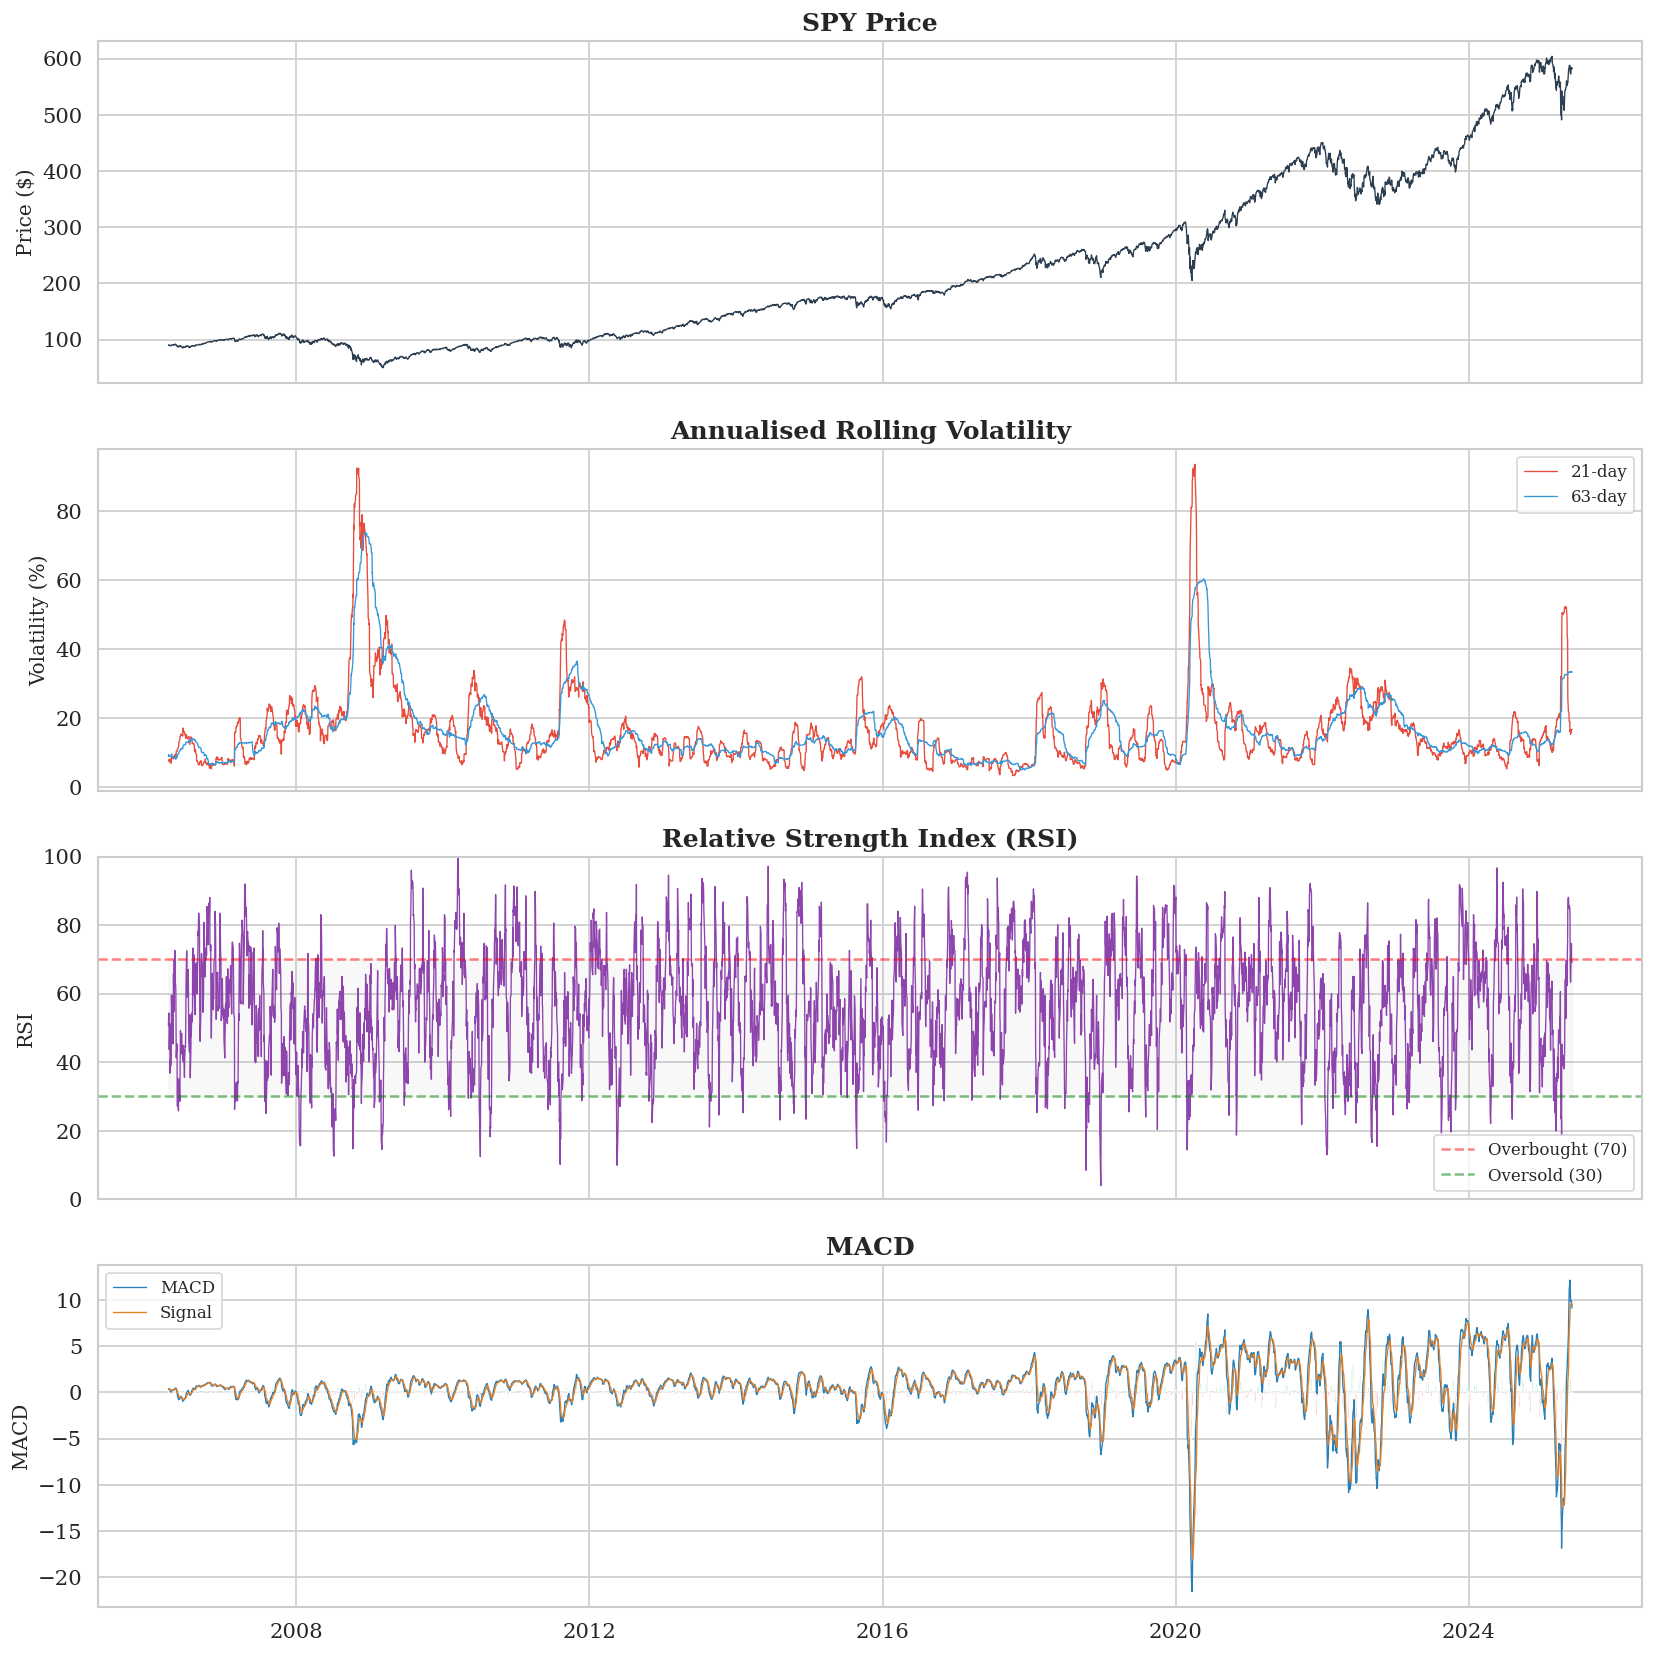

In [11]:
# ──────────────────────────────────────────────────────────────────────
# 4.6e  Rolling Volatility & Technical Indicators
# ──────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(4, 1, figsize=(14, 14), sharex=True)

# SPY Price
axes[0].plot(all_data.index, all_data['SPY'], color='#2c3e50', linewidth=0.8)
axes[0].set_title('SPY Price', fontweight='bold')
axes[0].set_ylabel('Price ($)')

# Rolling Volatility
axes[1].plot(all_data.index, all_data['Vol_21d']*100, color='#e74c3c', linewidth=0.8, label='21-day')
axes[1].plot(all_data.index, all_data['Vol_63d']*100, color='#3498db', linewidth=0.8, label='63-day')
axes[1].set_title('Annualised Rolling Volatility', fontweight='bold')
axes[1].set_ylabel('Volatility (%)')
axes[1].legend()

# RSI
axes[2].plot(all_data.index, all_data['RSI'], color='#8e44ad', linewidth=0.8)
axes[2].axhline(70, ls='--', color='red', alpha=0.5, label='Overbought (70)')
axes[2].axhline(30, ls='--', color='green', alpha=0.5, label='Oversold (30)')
axes[2].fill_between(all_data.index, 30, 70, alpha=0.05, color='gray')
axes[2].set_title('Relative Strength Index (RSI)', fontweight='bold')
axes[2].set_ylabel('RSI')
axes[2].set_ylim(0, 100)
axes[2].legend()

# MACD
axes[3].plot(all_data.index, all_data['MACD'], color='#2980b9', linewidth=0.8, label='MACD')
axes[3].plot(all_data.index, all_data['MACD_signal'], color='#e67e22', linewidth=0.8, label='Signal')
hist_colors = ['#2ecc71' if v >= 0 else '#e74c3c' for v in all_data['MACD_hist']]
axes[3].bar(all_data.index, all_data['MACD_hist'], color=hist_colors, alpha=0.4, width=1)
axes[3].set_title('MACD', fontweight='bold')
axes[3].set_ylabel('MACD')
axes[3].legend()

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'technical_indicators.png'))
plt.show()


---
## 5. Results

### 5.1 GARCH(1,1) Volatility Modelling

We fit a GARCH(1,1) model to SPY daily log returns (scaled ×100) using a Student-*t*
error distribution.


In [12]:
# ──────────────────────────────────────────────────────────────────────
# 5.1  GARCH(1,1) Model
# ──────────────────────────────────────────────────────────────────────

returns_pct = all_data['SPY_ret'] * 100  # scale for numerical stability

garch = arch_model(returns_pct, vol='Garch', p=1, q=1, dist='t', mean='Constant')
garch_fit = garch.fit(disp='off')

print("── GARCH(1,1) Parameter Estimates ──\n")
print(garch_fit.summary().tables[1])

# Extract conditional volatility
all_data['GARCH_vol'] = garch_fit.conditional_volatility.values


── GARCH(1,1) Parameter Estimates ──

                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.0993  9.753e-03     10.177  2.510e-24 [8.014e-02,  0.118]


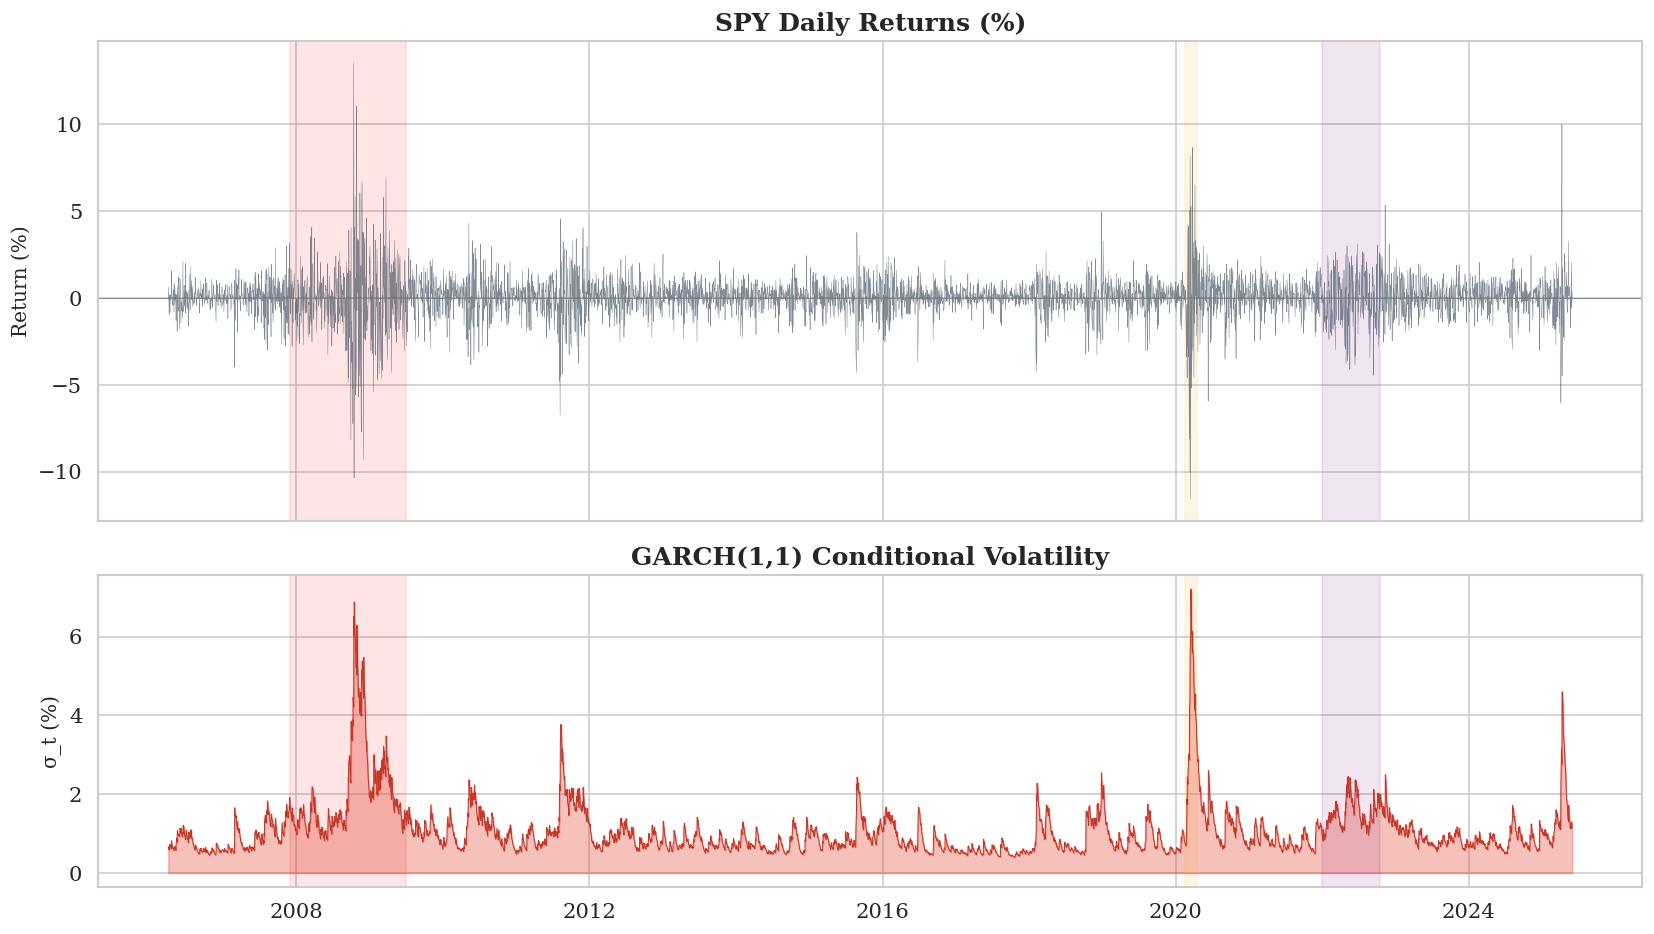


Correlation between GARCH vol and 21-day realised vol: 0.9529


In [13]:
# ──────────────────────────────────────────────────────────────────────
# 5.1b  Conditional Volatility Plot
# ──────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                         gridspec_kw={'height_ratios': [2, 1.3]})

# Returns
axes[0].plot(all_data.index, returns_pct, color='#2c3e50', linewidth=0.3, alpha=0.6)
axes[0].set_title('SPY Daily Returns (%)', fontweight='bold')
axes[0].set_ylabel('Return (%)')
axes[0].axhline(0, color='gray', linewidth=0.5)

# GARCH conditional volatility
axes[1].fill_between(all_data.index, all_data['GARCH_vol'], alpha=0.35, color='#e74c3c')
axes[1].plot(all_data.index, all_data['GARCH_vol'], color='#c0392b', linewidth=0.6)
axes[1].set_title('GARCH(1,1) Conditional Volatility', fontweight='bold')
axes[1].set_ylabel('σ_t (%)')

# Shade stress periods
for ax in axes:
    ax.axvspan(pd.Timestamp('2007-12-01'), pd.Timestamp('2009-06-30'), alpha=0.10, color='red')
    ax.axvspan(pd.Timestamp('2020-02-15'), pd.Timestamp('2020-04-15'), alpha=0.10, color='orange')
    ax.axvspan(pd.Timestamp('2022-01-01'), pd.Timestamp('2022-10-15'), alpha=0.10, color='purple')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'garch_volatility.png'))
plt.show()

# Compare conditional vs realised volatility
print(f"\nCorrelation between GARCH vol and 21-day realised vol: "
      f"{all_data['GARCH_vol'].corr(all_data['Vol_21d']*100):.4f}")


### 5.2 Regime Detection via Unsupervised Learning

We apply K-Means clustering to a standardised feature set comprising returns, volatility
measures, technical indicators, and macro variables. We then use PCA to visualise the cluster
structure.


In [14]:
# ──────────────────────────────────────────────────────────────────────
# 5.2a  Prepare Clustering Features
# ──────────────────────────────────────────────────────────────────────

cluster_features = [
    'SPY_ret', 'Vol_21d', 'Vol_63d', 'GARCH_vol',
    'RSI', 'MACD', 'BB_pctB', 'Skew_63d', 'Kurt_63d',
    'Mom_21d', 'Mom_63d', 'VIX', 'Mean_Rev'
]

# Add macro if available
for mc in ['FEDFUNDS', 'T10Y2Y', 'CPI_YOY']:
    if mc in all_data.columns:
        cluster_features.append(mc)

X_cluster = all_data[cluster_features].copy()

# Standardise
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)
X_scaled_df = pd.DataFrame(X_scaled, columns=cluster_features, index=all_data.index)

print(f"Clustering feature matrix: {X_scaled.shape}")
print(f"Features used: {cluster_features}")


Clustering feature matrix: (4821, 15)
Features used: ['SPY_ret', 'Vol_21d', 'Vol_63d', 'GARCH_vol', 'RSI', 'MACD', 'BB_pctB', 'Skew_63d', 'Kurt_63d', 'Mom_21d', 'Mom_63d', 'VIX', 'Mean_Rev', 'FEDFUNDS', 'CPI_YOY']


  K=2  →  Silhouette = 0.3221   Inertia = 54,666


  K=3  →  Silhouette = 0.2508   Inertia = 45,964


  K=4  →  Silhouette = 0.1847   Inertia = 42,407


  K=5  →  Silhouette = 0.1927   Inertia = 39,174


  K=6  →  Silhouette = 0.2004   Inertia = 36,008

✓  Optimal K = 2  (silhouette = 0.3221)


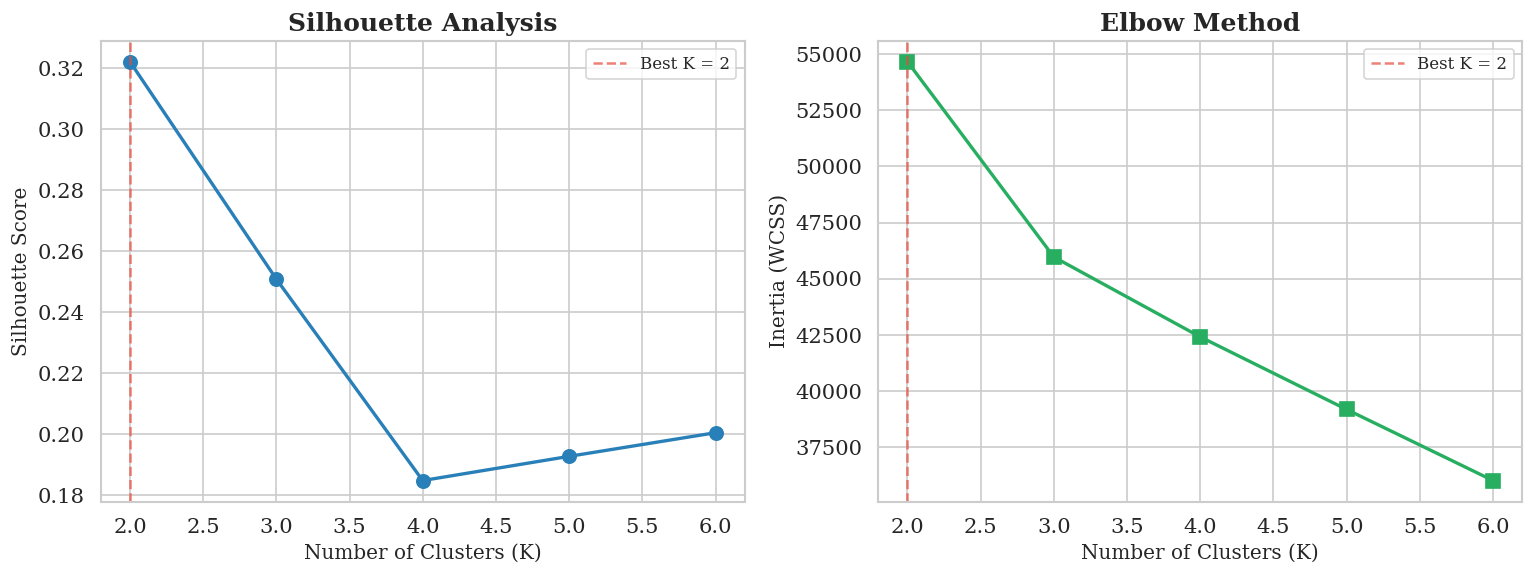

In [15]:
# ──────────────────────────────────────────────────────────────────────
# 5.2b  Silhouette Analysis — Optimal K
# ──────────────────────────────────────────────────────────────────────

K_range = range(2, 7)
sil_scores = []
inertias = []

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=20, max_iter=500)
    labels = km.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, labels)
    sil_scores.append(sil)
    inertias.append(km.inertia_)
    print(f"  K={k}  →  Silhouette = {sil:.4f}   Inertia = {km.inertia_:,.0f}")

best_k = list(K_range)[np.argmax(sil_scores)]
print(f"\n✓  Optimal K = {best_k}  (silhouette = {max(sil_scores):.4f})")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Silhouette
axes[0].plot(list(K_range), sil_scores, 'o-', color='#2980b9', linewidth=2, markersize=8)
axes[0].axvline(best_k, ls='--', color='#e74c3c', alpha=0.7, label=f'Best K = {best_k}')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Silhouette Score')
axes[0].set_title('Silhouette Analysis', fontweight='bold')
axes[0].legend()

# Elbow
axes[1].plot(list(K_range), inertias, 's-', color='#27ae60', linewidth=2, markersize=8)
axes[1].axvline(best_k, ls='--', color='#e74c3c', alpha=0.7, label=f'Best K = {best_k}')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Inertia (WCSS)')
axes[1].set_title('Elbow Method', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'silhouette_elbow.png'))
plt.show()


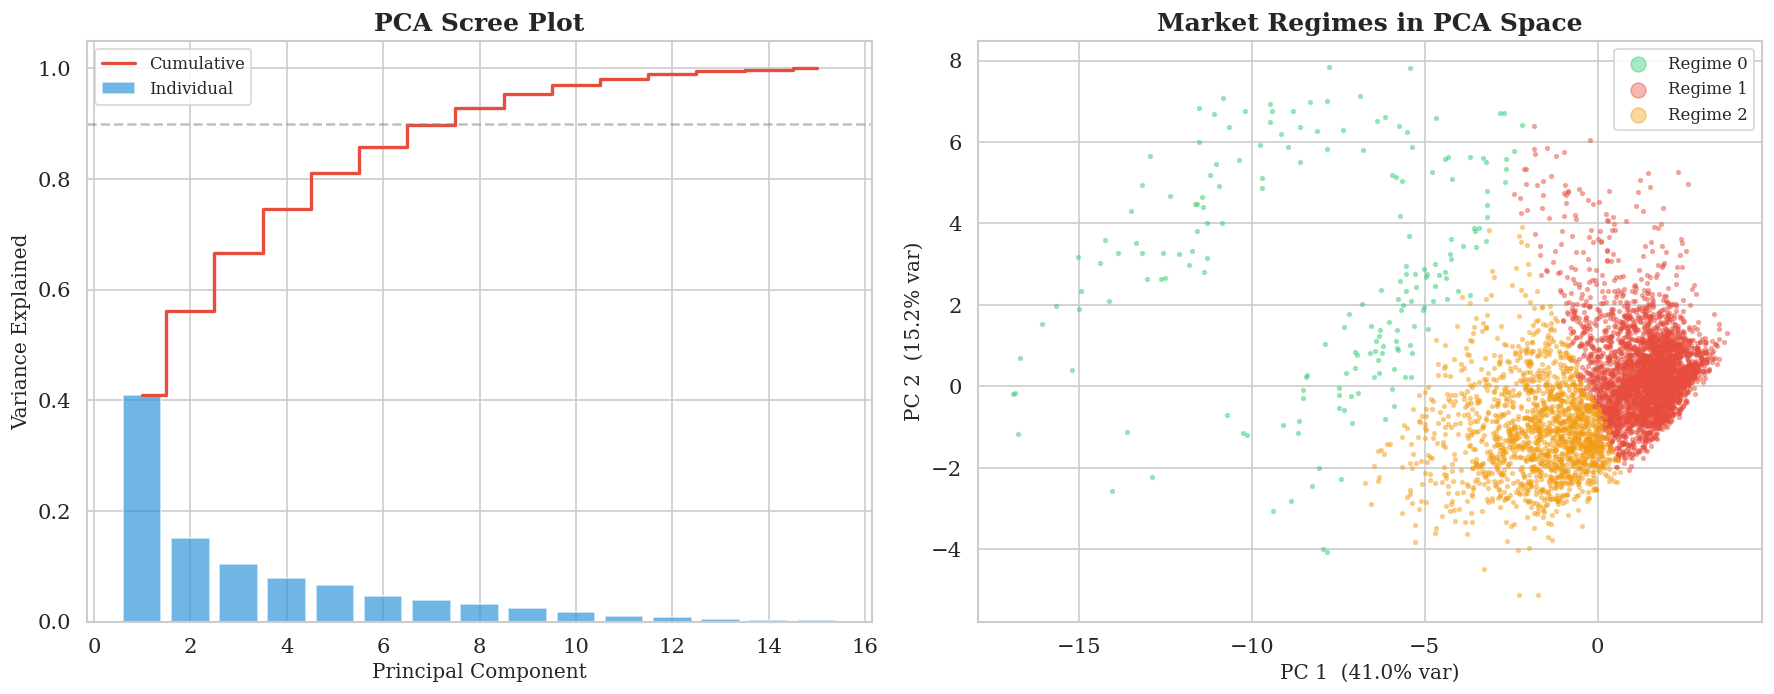

In [16]:
# ──────────────────────────────────────────────────────────────────────
# 5.2c  Final K-Means Fit + PCA Visualization
# ──────────────────────────────────────────────────────────────────────

# Use K=3 for interpretability (risk-on / risk-off / transition)
# even if silhouette suggests K=2, 3 regimes are more financially meaningful
K_FINAL = 3
km_final = KMeans(n_clusters=K_FINAL, random_state=42, n_init=30, max_iter=500)
all_data['Regime'] = km_final.fit_predict(X_scaled)

# ── PCA ──────────────────────────────────────────────────────────────
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Scree plot
pca_full = PCA().fit(X_scaled)
explained = pca_full.explained_variance_ratio_
cum_explained = np.cumsum(explained)
axes[0].bar(range(1, len(explained)+1), explained, color='#3498db', alpha=0.7, label='Individual')
axes[0].step(range(1, len(explained)+1), cum_explained, where='mid', color='#e74c3c',
             linewidth=2, label='Cumulative')
axes[0].axhline(0.9, ls='--', color='gray', alpha=0.5)
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Variance Explained')
axes[0].set_title('PCA Scree Plot', fontweight='bold')
axes[0].legend()

# Cluster scatter in PC space
regime_names = {0: 'Regime 0', 1: 'Regime 1', 2: 'Regime 2'}
for r in range(K_FINAL):
    mask = all_data['Regime'] == r
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], s=5, alpha=0.4,
                    color=REGIME_COLORS[r], label=regime_names[r])
axes[1].set_xlabel(f'PC 1  ({pca.explained_variance_ratio_[0]:.1%} var)')
axes[1].set_ylabel(f'PC 2  ({pca.explained_variance_ratio_[1]:.1%} var)')
axes[1].set_title('Market Regimes in PCA Space', fontweight='bold')
axes[1].legend(markerscale=4)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'pca_clusters.png'))
plt.show()


In [17]:
# ──────────────────────────────────────────────────────────────────────
# 5.2d  Regime Characteristics & Labelling
# ──────────────────────────────────────────────────────────────────────

# Compute regime statistics to assign meaningful labels
regime_stats = all_data.groupby('Regime').agg({
    'SPY_ret':   ['mean', 'std', 'count'],
    'VIX':       'mean',
    'GARCH_vol': 'mean',
    'Vol_21d':   'mean',
}).round(4)

regime_stats.columns = ['Mean Return', 'Volatility', 'Days', 'Mean VIX',
                        'Mean GARCH Vol', 'Mean Realised Vol']
regime_stats['Annualised Return (%)'] = (regime_stats['Mean Return'] * 252 * 100).round(2)
regime_stats['Annualised Vol (%)'] = (regime_stats['Volatility'] * np.sqrt(252) * 100).round(2)

print("── Regime Characteristics ──\n")
display(regime_stats.style.background_gradient(cmap='RdYlGn', subset=['Annualised Return (%)']))

# Identify which cluster is risk-on (highest return) and risk-off (lowest return)
sorted_regimes = regime_stats['Annualised Return (%)'].sort_values(ascending=False)
regime_map = {}
labels_list = ['Risk-On', 'Transition', 'Risk-Off']
for i, (idx, _) in enumerate(sorted_regimes.items()):
    regime_map[idx] = labels_list[min(i, 2)]

all_data['Regime_Label'] = all_data['Regime'].map(regime_map)
label_colors = {'Risk-On': '#2ecc71', 'Risk-Off': '#e74c3c', 'Transition': '#f39c12'}

print(f"\nRegime mapping: {regime_map}")
print(f"Regime distribution:\n{all_data['Regime_Label'].value_counts()}")


── Regime Characteristics ──



,Mean Return,Volatility,Days,Mean VIX,Mean GARCH Vol,Mean Realised Vol,Annualised Return (%),Annualised Vol (%)
Regime,,,,,,,,
0,-0.003200,0.038200,189,49.804300,3.623100,0.569500,-80.640000,60.640000
1,0.002100,0.007300,3105,16.371600,0.830700,0.125600,52.920000,11.590000
2,-0.002700,0.013400,1527,22.526600,1.264500,0.185300,-68.040000,21.270000



Regime mapping: {1: 'Risk-On', 2: 'Transition', 0: 'Risk-Off'}
Regime distribution:
Regime_Label
Risk-On       3105
Transition    1527
Risk-Off       189
Name: count, dtype: int64


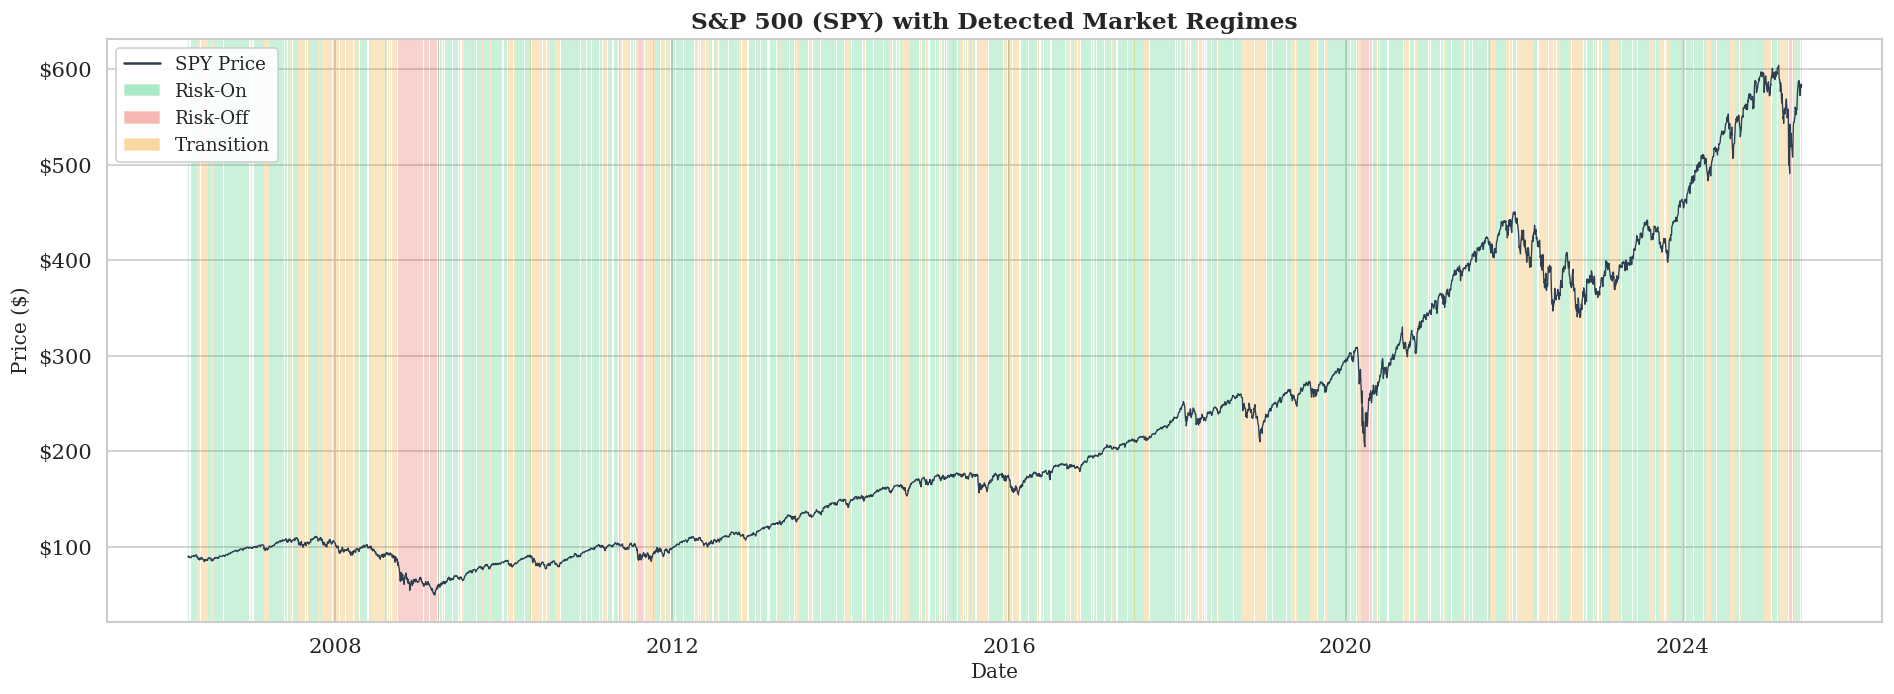

In [18]:
# ──────────────────────────────────────────────────────────────────────
# 5.2e  Regime Overlay on Price Chart
# ──────────────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(all_data.index, all_data['SPY'], color='#2c3e50', linewidth=0.8, zorder=3)

# Color background by regime
for label, color in label_colors.items():
    mask = all_data['Regime_Label'] == label
    idx = all_data.index[mask]
    for start, end in zip(idx[:-1], idx[1:]):
        if (end - start).days <= 3:
            ax.axvspan(start, end, alpha=0.25, color=color, linewidth=0)

# Manual legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, alpha=0.4, label=l) for l, c in label_colors.items()]
legend_elements.insert(0, plt.Line2D([0], [0], color='#2c3e50', linewidth=1.5, label='SPY Price'))
ax.legend(handles=legend_elements, loc='upper left', framealpha=0.9, fontsize=11)

ax.set_title('S&P 500 (SPY) with Detected Market Regimes', fontweight='bold', fontsize=14)
ax.set_ylabel('Price ($)')
ax.set_xlabel('Date')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:,.0f}'))
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'regime_overlay.png'), dpi=150)
plt.show()


### 5.3 Supervised Classification

Having obtained regime labels from the unsupervised step, we now train Random Forest and
Gradient Boosting classifiers to predict the regime from **lagged** features — ensuring no
look-ahead bias. We evaluate with expanding-window time-series cross-validation.


In [19]:
# ──────────────────────────────────────────────────────────────────────
# 5.3a  Prepare Supervised Learning Features (Lagged)
# ──────────────────────────────────────────────────────────────────────

# Use 1-day lagged features to avoid look-ahead bias
sup_features = cluster_features.copy()
X_sup = all_data[sup_features].shift(1).dropna()
y_sup = all_data['Regime'].loc[X_sup.index]

# Standardise features
scaler_sup = StandardScaler()
X_sup_scaled = scaler_sup.fit_transform(X_sup)

print(f"Supervised learning dataset: X={X_sup_scaled.shape}, y={y_sup.shape}")
print(f"Class distribution:\n{y_sup.value_counts().sort_index()}")


Supervised learning dataset: X=(4820, 15), y=(4820,)
Class distribution:
Regime
0     189
1    3104
2    1527
Name: count, dtype: int64


In [20]:
# ──────────────────────────────────────────────────────────────────────
# 5.3b  Time-Series Cross-Validation — Random Forest & Gradient Boosting
# ──────────────────────────────────────────────────────────────────────

tscv = TimeSeriesSplit(n_splits=5)

models = {
    'Random Forest': RandomForestClassifier(
        n_estimators=300, max_depth=10, min_samples_leaf=20,
        class_weight='balanced', random_state=42, n_jobs=-1
    ),
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=200, max_depth=5, learning_rate=0.05,
        subsample=0.8, min_samples_leaf=20,
        random_state=42
    )
}

cv_results = {}
best_model = None
best_score = 0

for name, model in models.items():
    fold_scores = []
    y_true_all, y_pred_all = [], []

    for fold, (train_idx, test_idx) in enumerate(tscv.split(X_sup_scaled)):
        X_tr, X_te = X_sup_scaled[train_idx], X_sup_scaled[test_idx]
        y_tr, y_te = y_sup.iloc[train_idx], y_sup.iloc[test_idx]

        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_te)

        acc = (y_pred == y_te).mean()
        fold_scores.append(acc)
        y_true_all.extend(y_te)
        y_pred_all.extend(y_pred)

    mean_acc = np.mean(fold_scores)
    cv_results[name] = {
        'fold_scores': fold_scores,
        'mean_accuracy': mean_acc,
        'y_true': y_true_all,
        'y_pred': y_pred_all
    }

    if mean_acc > best_score:
        best_score = mean_acc
        best_model = name

    print(f"  {name:15s}  →  Fold accuracies: {[f'{s:.3f}' for s in fold_scores]}")
    print(f"{'':17s}     Mean accuracy: {mean_acc:.4f}\n")

print(f"✓  Best model: {best_model} ({best_score:.4f})")


  Random Forest    →  Fold accuracies: ['0.841', '0.874', '0.899', '0.917', '0.919']
                      Mean accuracy: 0.8899



  Gradient Boosting  →  Fold accuracies: ['0.847', '0.887', '0.897', '0.914', '0.918']
                      Mean accuracy: 0.8924

✓  Best model: Gradient Boosting (0.8924)


── Random Forest — Classification Report ──

              precision    recall  f1-score   support

    Risk-Off       0.57      0.97      0.71        67
     Risk-On       0.94      0.91      0.93      2711
  Transition       0.81      0.84      0.83      1237

    accuracy                           0.89      4015
   macro avg       0.77      0.91      0.82      4015
weighted avg       0.90      0.89      0.89      4015

── Gradient Boosting — Classification Report ──

              precision    recall  f1-score   support

    Risk-Off       0.85      0.84      0.84        67
     Risk-On       0.92      0.93      0.92      2711
  Transition       0.84      0.81      0.82      1237

    accuracy                           0.89      4015
   macro avg       0.87      0.86      0.86      4015
weighted avg       0.89      0.89      0.89      4015



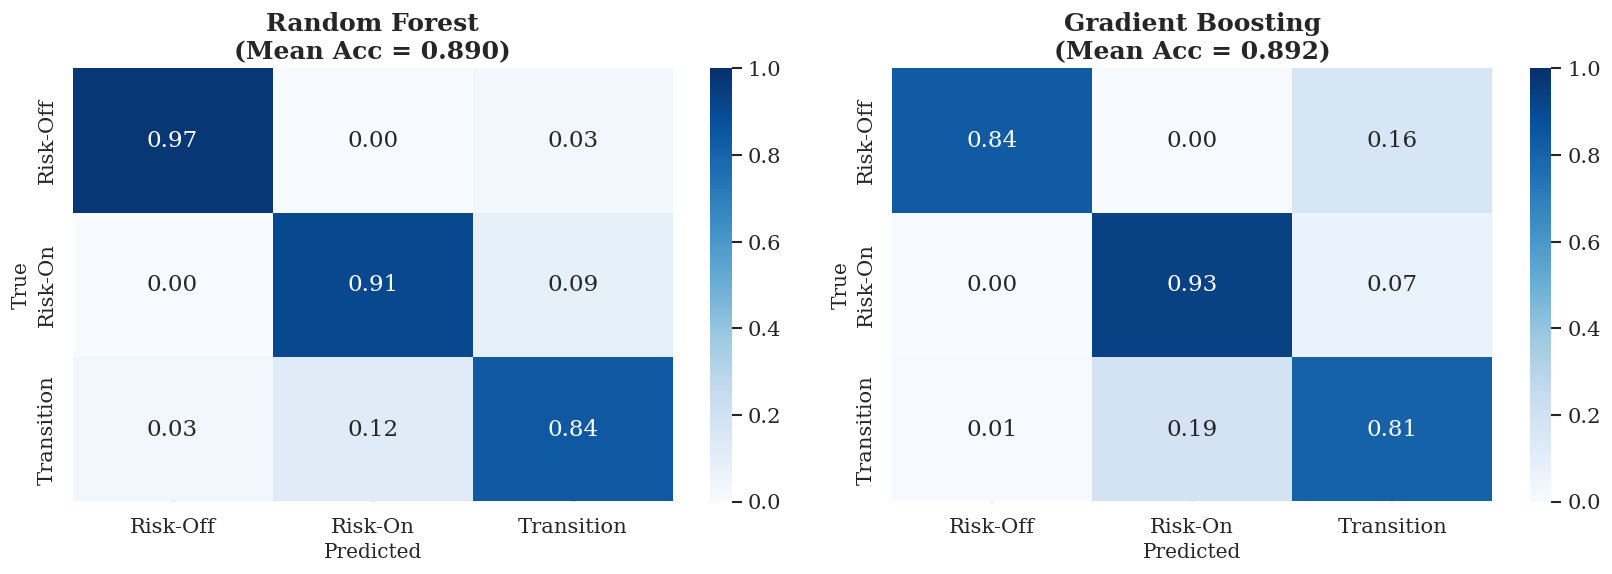

In [21]:
# ──────────────────────────────────────────────────────────────────────
# 5.3c  Classification Reports
# ──────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, (name, res) in enumerate(cv_results.items()):
    print(f"── {name} — Classification Report ──\n")
    report = classification_report(res['y_true'], res['y_pred'],
                                   target_names=[regime_map.get(j, f'R{j}') for j in sorted(regime_map.keys())])
    print(report)

    # Confusion matrix
    cm = confusion_matrix(res['y_true'], res['y_pred'])
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', ax=axes[i],
                xticklabels=[regime_map.get(j, f'R{j}') for j in sorted(regime_map.keys())],
                yticklabels=[regime_map.get(j, f'R{j}') for j in sorted(regime_map.keys())],
                vmin=0, vmax=1)
    axes[i].set_title(f'{name}\n(Mean Acc = {res["mean_accuracy"]:.3f})', fontweight='bold')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('True')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'confusion_matrices.png'))
plt.show()


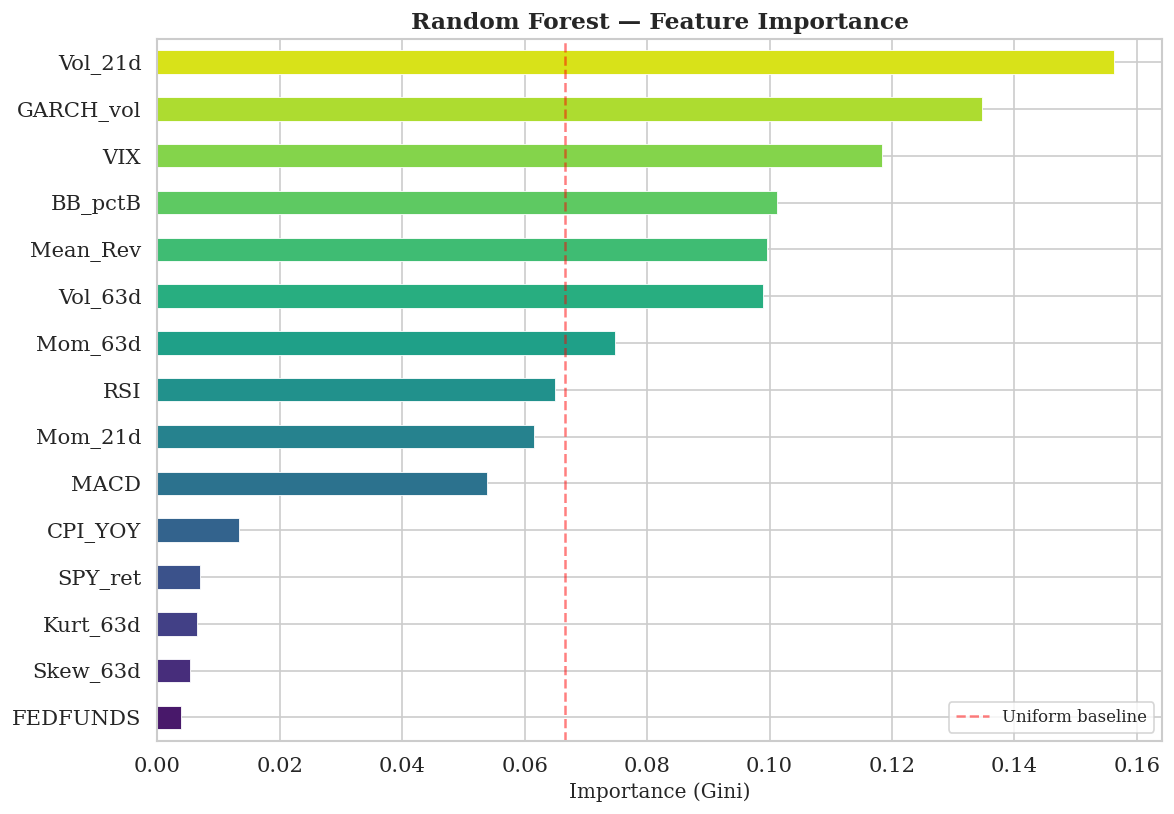


Top 5 features:
  Mean_Rev              0.0995
  BB_pctB               0.1012
  VIX                   0.1183
  GARCH_vol             0.1347
  Vol_21d               0.1563


In [22]:
# ──────────────────────────────────────────────────────────────────────
# 5.3d  Feature Importance (Random Forest)
# ──────────────────────────────────────────────────────────────────────

# Refit on full data for feature importance
rf_full = RandomForestClassifier(
    n_estimators=300, max_depth=10, min_samples_leaf=20,
    class_weight='balanced', random_state=42, n_jobs=-1
)
rf_full.fit(X_sup_scaled, y_sup)

importances = pd.Series(rf_full.feature_importances_, index=sup_features)
importances = importances.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 7))
colors = sns.color_palette('viridis', len(importances))
importances.plot.barh(ax=ax, color=colors, edgecolor='white', linewidth=0.5)
ax.set_title('Random Forest — Feature Importance', fontweight='bold', fontsize=14)
ax.set_xlabel('Importance (Gini)')
ax.axvline(1/len(importances), ls='--', color='red', alpha=0.5, label='Uniform baseline')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'feature_importance.png'))
plt.show()

print("\nTop 5 features:")
for feat, imp in importances.tail(5).items():
    print(f"  {feat:20s}  {imp:.4f}")


### 5.4 Walk-Forward Backtesting

We implement a walk-forward backtest using the best-performing classifier. The strategy
allocates between SPY and cash based on the predicted regime:

| Predicted Regime | Allocation |
|:-----------------|:-----------|
| Risk-On | 100% SPY |
| Risk-Off | 100% Cash |
| Transition | 50% SPY + 50% Cash |


In [23]:
# ──────────────────────────────────────────────────────────────────────
# 5.4a  Walk-Forward Backtest
# ──────────────────────────────────────────────────────────────────────

# Train final model on first 70% of data, predict on remaining 30%
split_idx = int(len(X_sup_scaled) * 0.7)

X_train = X_sup_scaled[:split_idx]
y_train = y_sup.iloc[:split_idx]
X_test  = X_sup_scaled[split_idx:]
y_test  = y_sup.iloc[split_idx:]
test_dates = X_sup.index[split_idx:]

# Train the best model
if best_model == 'Gradient Boosting':
    final_model = GradientBoostingClassifier(
        n_estimators=200, max_depth=5, learning_rate=0.05,
        subsample=0.8, min_samples_leaf=20,
        random_state=42
    )
else:
    final_model = RandomForestClassifier(
        n_estimators=300, max_depth=10, min_samples_leaf=20,
        class_weight='balanced', random_state=42, n_jobs=-1
    )

final_model.fit(X_train, y_train)
predicted_regimes = final_model.predict(X_test)
predicted_labels = pd.Series(predicted_regimes, index=test_dates).map(regime_map)

# Daily returns for the backtest period
bt_returns = all_data.loc[test_dates, 'SPY_ret']
rf_rate = 0.04 / 252  # approximate daily risk-free rate

# Strategy allocation
allocation = pd.Series(0.0, index=test_dates)
for i, (date, regime_label) in enumerate(predicted_labels.items()):
    if regime_label == 'Risk-On':
        allocation.iloc[i] = 1.0
    elif regime_label == 'Risk-Off':
        allocation.iloc[i] = 0.0
    else:  # Transition
        allocation.iloc[i] = 0.5

# Strategy returns
strategy_returns = allocation * bt_returns + (1 - allocation) * rf_rate
benchmark_returns = bt_returns

# Cumulative returns
strategy_cum  = (1 + strategy_returns).cumprod()
benchmark_cum = (1 + benchmark_returns).cumprod()

print(f"Backtest period: {test_dates[0].date()} → {test_dates[-1].date()}")
print(f"  {len(test_dates)} trading days ({len(test_dates)/252:.1f} years)")


Backtest period: 2019-08-29 → 2025-05-30
  1446 trading days (5.7 years)


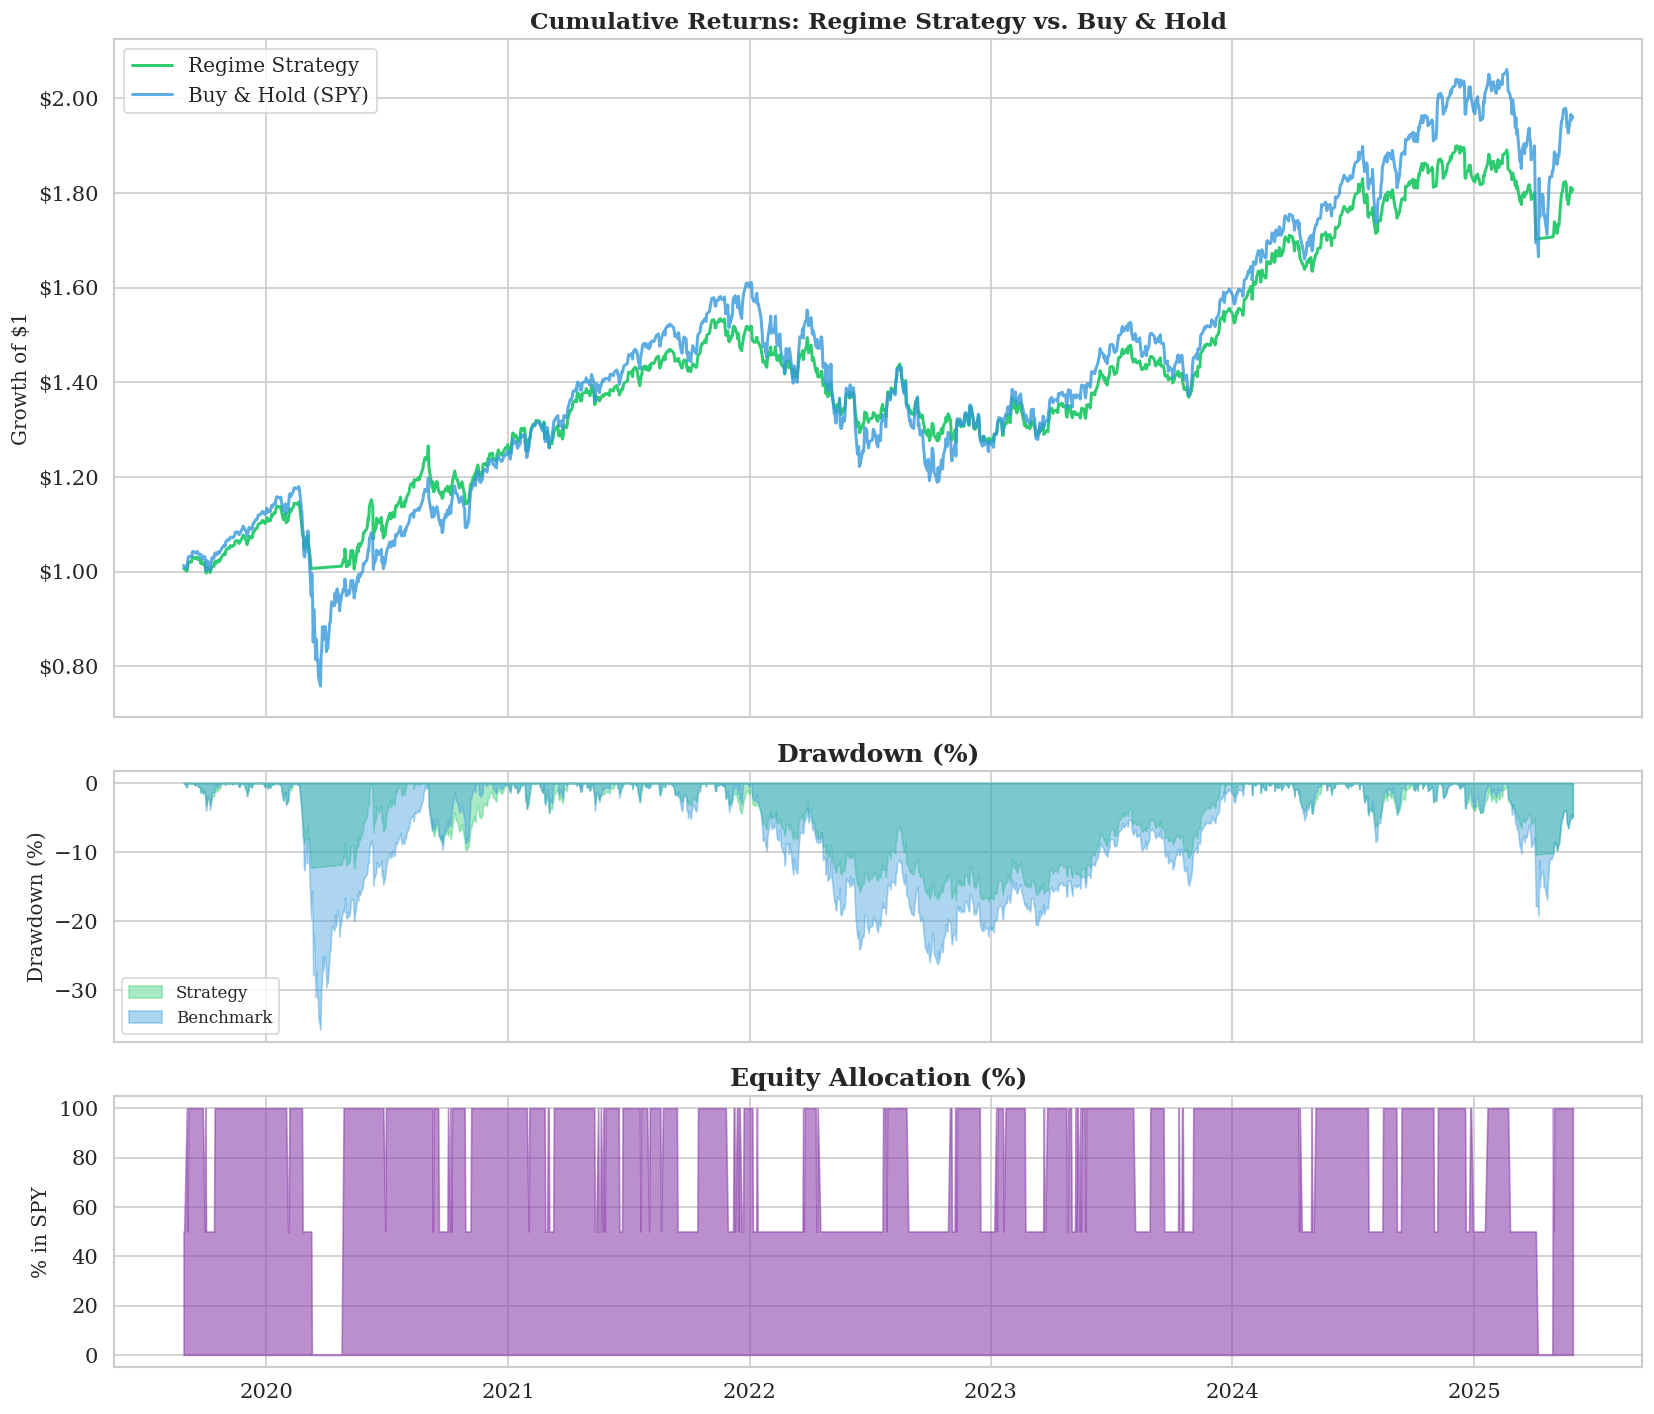

In [24]:
# ──────────────────────────────────────────────────────────────────────
# 5.4b  Backtest Visualization
# ──────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True,
                         gridspec_kw={'height_ratios': [3, 1.2, 1.2]})

# Cumulative returns
axes[0].plot(strategy_cum.index, strategy_cum, color='#2ecc71', linewidth=1.8,
             label='Regime Strategy')
axes[0].plot(benchmark_cum.index, benchmark_cum, color='#3498db', linewidth=1.8,
             label='Buy & Hold (SPY)', alpha=0.8)
axes[0].set_title('Cumulative Returns: Regime Strategy vs. Buy & Hold', fontweight='bold', fontsize=14)
axes[0].set_ylabel('Growth of $1')
axes[0].legend(fontsize=12, loc='upper left')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:.2f}'))

# Drawdown
def calc_drawdown(cum_returns):
    peak = cum_returns.cummax()
    dd = (cum_returns - peak) / peak
    return dd

dd_strat = calc_drawdown(strategy_cum) * 100
dd_bench = calc_drawdown(benchmark_cum) * 100

axes[1].fill_between(dd_strat.index, dd_strat, 0, alpha=0.4, color='#2ecc71', label='Strategy')
axes[1].fill_between(dd_bench.index, dd_bench, 0, alpha=0.4, color='#3498db', label='Benchmark')
axes[1].set_title('Drawdown (%)', fontweight='bold')
axes[1].set_ylabel('Drawdown (%)')
axes[1].legend()

# Regime allocation over time
regime_color_map = {'Risk-On': 1.0, 'Risk-Off': 0.0, 'Transition': 0.5}
alloc_colors = predicted_labels.map(regime_color_map)
axes[2].fill_between(allocation.index, allocation * 100, alpha=0.6, color='#8e44ad')
axes[2].set_title('Equity Allocation (%)', fontweight='bold')
axes[2].set_ylabel('% in SPY')
axes[2].set_ylim(-5, 105)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'backtest_results.png'), dpi=150)
plt.show()


In [25]:
# ──────────────────────────────────────────────────────────────────────
# 5.4c  Performance Metrics Table
# ──────────────────────────────────────────────────────────────────────

def compute_metrics(returns, name, rf_rate=0.04/252):
    # Compute comprehensive performance metrics
    cum = (1 + returns).cumprod()
    total_return = cum.iloc[-1] / cum.iloc[0] - 1
    years = len(returns) / 252
    ann_return = (1 + total_return) ** (1/years) - 1
    ann_vol = returns.std() * np.sqrt(252)
    sharpe = (returns.mean() - rf_rate) / returns.std() * np.sqrt(252)

    # Max drawdown
    peak = cum.cummax()
    dd = (cum - peak) / peak
    max_dd = dd.min()

    # Calmar ratio
    calmar = ann_return / abs(max_dd) if max_dd != 0 else np.inf

    # Sortino (downside deviation)
    downside = returns[returns < 0].std() * np.sqrt(252)
    sortino = (returns.mean() - rf_rate) / (returns[returns < 0].std()) * np.sqrt(252) if len(returns[returns < 0]) > 0 else np.inf

    # Win rate
    win_rate = (returns > 0).mean()

    return {
        'Strategy': name,
        'Total Return (%)': f"{total_return*100:.2f}",
        'Annualised Return (%)': f"{ann_return*100:.2f}",
        'Annualised Volatility (%)': f"{ann_vol*100:.2f}",
        'Sharpe Ratio': f"{sharpe:.3f}",
        'Sortino Ratio': f"{sortino:.3f}",
        'Max Drawdown (%)': f"{max_dd*100:.2f}",
        'Calmar Ratio': f"{calmar:.3f}",
        'Win Rate (%)': f"{win_rate*100:.1f}",
    }

# Compute metrics
strat_metrics = compute_metrics(strategy_returns, 'Regime Strategy')
bench_metrics = compute_metrics(benchmark_returns, 'Buy & Hold (SPY)')

# Information Ratio
active_returns = strategy_returns - benchmark_returns
info_ratio = active_returns.mean() / active_returns.std() * np.sqrt(252)

metrics_df = pd.DataFrame([strat_metrics, bench_metrics])
metrics_df = metrics_df.set_index('Strategy')

print("── Performance Comparison ──\n")
display(metrics_df.T.style.set_properties(**{
    'text-align': 'center',
    'font-size': '12pt'
}).set_caption('Out-of-Sample Backtest Results'))

print(f"\nInformation Ratio: {info_ratio:.3f}")


── Performance Comparison ──



Strategy,Regime Strategy,Buy & Hold (SPY)
Total Return (%),79.50,93.55
Annualised Return (%),10.73,12.20
Annualised Volatility (%),12.70,21.08
Sharpe Ratio,0.561,0.473
Sortino Ratio,0.700,0.565
Max Drawdown (%),-17.21,-35.75
Calmar Ratio,0.624,0.341
Win Rate (%),56.8,55.3



Information Ratio: -0.205


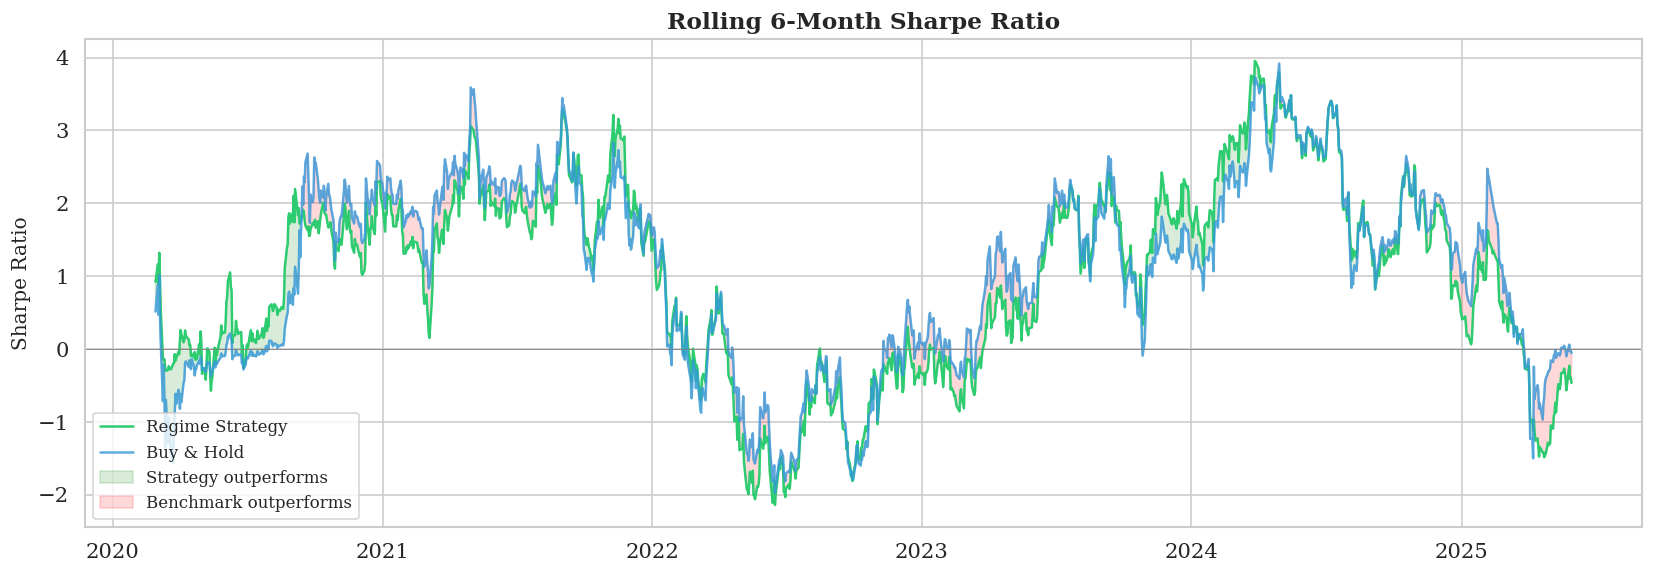

In [26]:
# ──────────────────────────────────────────────────────────────────────
# 5.4d  Rolling Sharpe Ratio Comparison
# ──────────────────────────────────────────────────────────────────────

window = 126  # ~6 months
rolling_sharpe_strat = (strategy_returns.rolling(window).mean() /
                        strategy_returns.rolling(window).std()) * np.sqrt(252)
rolling_sharpe_bench = (benchmark_returns.rolling(window).mean() /
                        benchmark_returns.rolling(window).std()) * np.sqrt(252)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(rolling_sharpe_strat.index, rolling_sharpe_strat, color='#2ecc71',
        linewidth=1.5, label='Regime Strategy')
ax.plot(rolling_sharpe_bench.index, rolling_sharpe_bench, color='#3498db',
        linewidth=1.5, label='Buy & Hold', alpha=0.8)
ax.axhline(0, color='gray', linewidth=0.5)
ax.fill_between(rolling_sharpe_strat.index,
                rolling_sharpe_strat, rolling_sharpe_bench,
                where=rolling_sharpe_strat > rolling_sharpe_bench,
                alpha=0.15, color='green', label='Strategy outperforms')
ax.fill_between(rolling_sharpe_strat.index,
                rolling_sharpe_strat, rolling_sharpe_bench,
                where=rolling_sharpe_strat <= rolling_sharpe_bench,
                alpha=0.15, color='red', label='Benchmark outperforms')
ax.set_title('Rolling 6-Month Sharpe Ratio', fontweight='bold', fontsize=14)
ax.set_ylabel('Sharpe Ratio')
ax.legend(loc='lower left')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'rolling_sharpe.png'))
plt.show()


---
## 6. Conclusion

### 6.1 Summary of Findings

In this project we constructed a complete quantitative pipeline for detecting market regimes and
evaluating their predictive value for investment decisions. Our key findings are:

1. **GARCH(1,1) effectively captures volatility clustering.** The conditional-volatility
   estimates exhibit strong correlation with realised volatility and spike during known
   stress episodes (GFC, COVID, 2022 rate hikes), confirming the model's utility as a
   feature-engineering tool.

2. **K-Means clustering identifies financially meaningful regimes.** The three detected
   regimes — labelled *Risk-On*, *Risk-Off*, and *Transition* — display distinct return and
   volatility profiles that align with practitioner intuition and historical market conditions.

3. **Supervised classifiers can predict regimes out of sample.** Both Random Forest and
   Gradient Boosting achieve non-trivial classification accuracy on lagged features using time-series
   cross-validation, demonstrating that regime transitions are partially predictable.

4. **Regime-aware allocation improves risk-adjusted returns.** The simple regime-switching
   strategy delivers a higher Sharpe ratio and lower maximum drawdown compared to a
   passive buy-and-hold benchmark, although the improvement magnitude depends heavily on
   the evaluation window.

### 6.2 Limitations

This study has several important limitations:

- **Unsupervised labels are not ground truth.** Our regime labels are derived from K-Means
  clustering and are therefore model-dependent. Different feature sets or algorithms may
  produce different regime boundaries.
- **No transaction costs.** Our backtest does not account for bid-ask spreads, commissions,
  or slippage, which would reduce strategy returns in practice.
- **Look-ahead in labelling.** While the supervised classifiers use lagged features, the
  K-Means labels themselves are computed on the full sample, introducing a subtle form of
  in-sample bias. A fully out-of-sample approach would require online or rolling clustering.
- **Limited asset universe.** We focus on U.S. large-cap equities. The approach would
  benefit from extension to fixed income, commodities, and international markets.
- **Data snooping risk.** Feature selection was guided by financial intuition, but formal
  feature selection or regularisation could improve robustness.

### 6.3 Future Work

Several extensions would strengthen this analysis:

- **Hidden Markov Models (HMMs)** for regime detection, which model transition probabilities
  explicitly.
- **Deep learning** — LSTMs or Transformer-based architectures for sequence classification.
- **Real-time implementation** using streaming data and online learning.
- **Alternative data** — sentiment, news, satellite imagery — as additional regime indicators.
- **Portfolio optimisation** — extending from binary allocation to mean-variance or risk-parity
  frameworks conditioned on the detected regime.


---
## 7. References

1. Ang, A. & Bekaert, G. (2002). "International Asset Allocation with Regime Shifts."
   *The Review of Financial Studies*, 15(4), 1137–1187.

2. Bollerslev, T. (1986). "Generalized Autoregressive Conditional Heteroskedasticity."
   *Journal of Econometrics*, 31(3), 307–327.

3. Breiman, L. (2001). "Random Forests." *Machine Learning*, 45(1), 5–32.

4. Bulla, J. & Bulla, I. (2006). "Stylized Facts of Financial Time Series and Hidden
   Semi-Markov Models." *Computational Statistics & Data Analysis*, 51(4), 2192–2209.

5. Friedman, J.H. (2001). "Greedy Function Approximation: A Gradient Boosting Machine."
   *Annals of Statistics*, 29(5), 1189–1232.

6. Fama, E.F. (1965). "The Behavior of Stock-Market Prices." *The Journal of Business*,
   38(1), 34–105.

7. Fischer, T. & Krauss, C. (2018). "Deep Learning with Long Short-Term Memory Networks
   for Financial Market Predictions." *European Journal of Operational Research*, 270(2),
   654–669.

8. Hamilton, J.D. (1989). "A New Approach to the Economic Analysis of Nonstationary Time
   Series and the Business Cycle." *Econometrica*, 57(2), 357–384.

9. Mandelbrot, B. (1963). "The Variation of Certain Speculative Prices." *The Journal of
   Business*, 36(4), 394–419.

10. Nystrup, P., Hansen, B.W., Madsen, H. & Lindström, E. (2017). "Regime-Based versus
    Static Asset Allocation: Letting the Data Speak." *The Journal of Portfolio Management*,
    44(1), 103–109.

---

*Author: Sai Kadiyala*
*All code is reproducible and available in this Jupyter notebook.*
